# Test for augmenated training Mels
- We used this script to assure the correct parameters for each augmentated technique to avoid ruined the audio signal. It is run a single audio randomly.

In [1]:
import IPython.display as display
from IPython.display import Audio, display
from PIL import Image

import random
import numpy as np
import os
import pathlib
import pandas as pd
import re
import seaborn as sns
import librosa.display
import librosa
import soundfile as sf

import matplotlib.cm as cm
import matplotlib.pyplot as plt

from audiomentations import AddGaussianNoise
from audiomentations import AddColorNoise
from audiomentations import LoudnessNormalization
from audiomentations import TanhDistortion
from audiomentations import AddGaussianNoise
from audiomentations import Limiter
from audiomentations import HighShelfFilter
from audiomentations import LowShelfFilter
from audiomentations import RepeatPart


from pedalboard import Pedalboard, Chorus
from pedalboard import Pedalboard, Phaser
from pedalboard import Pedalboard, Reverb




# 0. Basic setup

In [2]:
# LABELS PATHS (CSVs)
ORG_LABELS_TRAIN = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_ok_full_+++.csv"
AUG_LABELS_TRAIN = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_aug_ok_full_+++.csv"

train_df = pd.read_csv(ORG_LABELS_TRAIN)   # wav originales
train_df_aug  = pd.read_csv(AUG_LABELS_TRAIN)    # wav aumentados

In [10]:
# AUDIO PATHS (FOLDERS)
ORG_AUDIO_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\data\org_audio_pb"
AUG_AUDIO_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_ok_full_+++"

In [4]:
# MELS PATHS (FOLDERS)
ORG_MELS_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\org_mels_ok_full_+++"
AUG_MELS_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\org_mels_ok_full_+++"

### Function

In [6]:
# function for choose random audio

def select_audio_random(df, org_audio_dir):
    row = df.sample(1).iloc[0]
    fname = row["filename"]
    path = os.path.join(org_audio_dir, fname)
    return fname, path


# 1. Techniques

### Trim dynamic

In [ ]:
# PARAMETERS

DROP_DB_DESEADO = 5      # how many dB cut from the minimum RMS
frame_length = 2048
hop_length = 512

In [ ]:
# FUNCTION

def trim_dynamic_min_rms(y, sr, drop_db_target=5):
  
    # compute RMS per frame
    rms = librosa.feature.rms(y=y,
                              frame_length=frame_length,
                              hop_length=hop_length)[0]

    # convert RMS to dB
    rms_db = librosa.amplitude_to_db(rms, ref=np.max)

    # maximum, minimum and dynamic range
    max_rms_db = np.max(rms_db)
    min_rms_db = np.min(rms_db)
    rms_range = max_rms_db - min_rms_db

    # compute desired threshold
    #
    # we want to trim EXACTLY drop_db above the minimum RMS:
    # desired_threshold = min_rms_db + drop_db_target
    
    desired_threshold = min_rms_db + drop_db_target

    # if signal does NOT fall enough in dB
    if rms_range < drop_db_target:
        # soft adjustment: trim as much as possible
        applied_threshold = min_rms_db + (rms_range - 1)
    else:
        applied_threshold = desired_threshold

    # Convert to top_db for librosa:
    #
    # librosa uses:
    #   threshold = max_rms_db - top_db
    #
    # we want that threshold to be applied_threshold ⇒
    #   max_rms_db - top_db = applied_threshold
    #   top_db = max_rms_db - applied_threshold

    top_db_auto = max_rms_db - applied_threshold

    # sanity:
    if top_db_auto < 0.5:
        top_db_auto = 0.5

    # apply actual trim
    y_trim, idx = librosa.effects.trim(
        y,
        top_db=top_db_auto,
        frame_length=frame_length,
        hop_length=hop_length
    )

    return (y_trim, idx, top_db_auto,
            rms_db, max_rms_db, min_rms_db, rms_range,
            desired_threshold, applied_threshold)

# DIAGNOSTIC

def diagnostic_trim_dynamic(drop_db):

    print(f"✅ === DYNAMIC TRIM DIAGNOSTIC (drop_db_target = {drop_db}) ===\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Chosen audio: {fname}")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # apply dynamic TRIM based on MINIMUM RMS
    (y_trim, idx, top_db_auto,
     rms_db, max_rms_db, min_rms_db, rms_range,
     desired_threshold, applied_threshold) = trim_dynamic_min_rms(y, sr, drop_db)

    print("\n📌 KEY RESULTS:")
    print(f"   - min_rms_db        = {min_rms_db:.2f} dB")
    print(f"   - desired threshold = {desired_threshold:.2f} dB")
    print(f"   - applied threshold = {applied_threshold:.2f} dB")
    print(f"   - top_db_auto       = {top_db_auto:.2f}")
    print(f"   - trim index        = {idx}")
    print(f"   - total rms_range   = {rms_range:.2f} dB\n")

    # RMS plot with trimmed region
    plt.figure(figsize=(20, 8))
    plt.plot(rms_db, label="RMS Energy (dB)", linewidth=2)

    plt.axhline(max_rms_db, color="green", linestyle="--",
                label=f"Max RMS {max_rms_db:.2f} dB")
    plt.axhline(min_rms_db, color="blue", linestyle="--",
                label=f"Min RMS {min_rms_db:.2f} dB")
    plt.axhline(desired_threshold, color="orange", linestyle="--",
                label=f"Desired threshold (min + {drop_db}) = {desired_threshold:.2f} dB")
    plt.axhline(applied_threshold, color="red", linestyle="--",
                label=f"Applied threshold = {applied_threshold:.2f} dB")

    silent_frames = rms_db < applied_threshold
    plt.fill_between(
        np.arange(len(rms_db)),
        rms_db,
        applied_threshold,
        where=silent_frames,
        color="red",
        alpha=0.3,
        label="Trimmed region"
    )

    plt.title(
        f"Threshold Computation Based on MINIMUM RMS\n"
        f"(min={min_rms_db:.2f}, drop={drop_db} dB, applied={applied_threshold:.2f}, top_db_final={top_db_auto:.2f})",
        fontsize=14
    )
    plt.xlabel("Frames")
    plt.ylabel("RMS (dB)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Mel-spectrogram comparison (original vs trimmed)
    mel_o = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr), ref=np.max)
    mel_t = librosa.power_to_db(librosa.feature.melspectrogram(y=y_trim, sr=sr), ref=np.max)

    plt.figure(figsize=(20, 6))
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis="time", y_axis="mel", cmap="magma")
    plt.title("Original Mel")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_t, sr=sr, x_axis="time", y_axis="mel", cmap="magma")
    plt.title(f"Trimmed Mel (top_db={top_db_auto:.2f})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()



✅ === DYNAMIC TRIM DIAGNOSTIC (drop_db_target = 5) ===

🎵 Chosen audio: 039_10_P2.wav

📌 KEY RESULTS:
   - min_rms_db        = -15.79 dB
   - desired threshold = -10.79 dB
   - applied threshold = -10.79 dB
   - top_db_auto       = 10.79
   - trim index        = [ 1536 88064]
   - total rms_range   = 15.79 dB



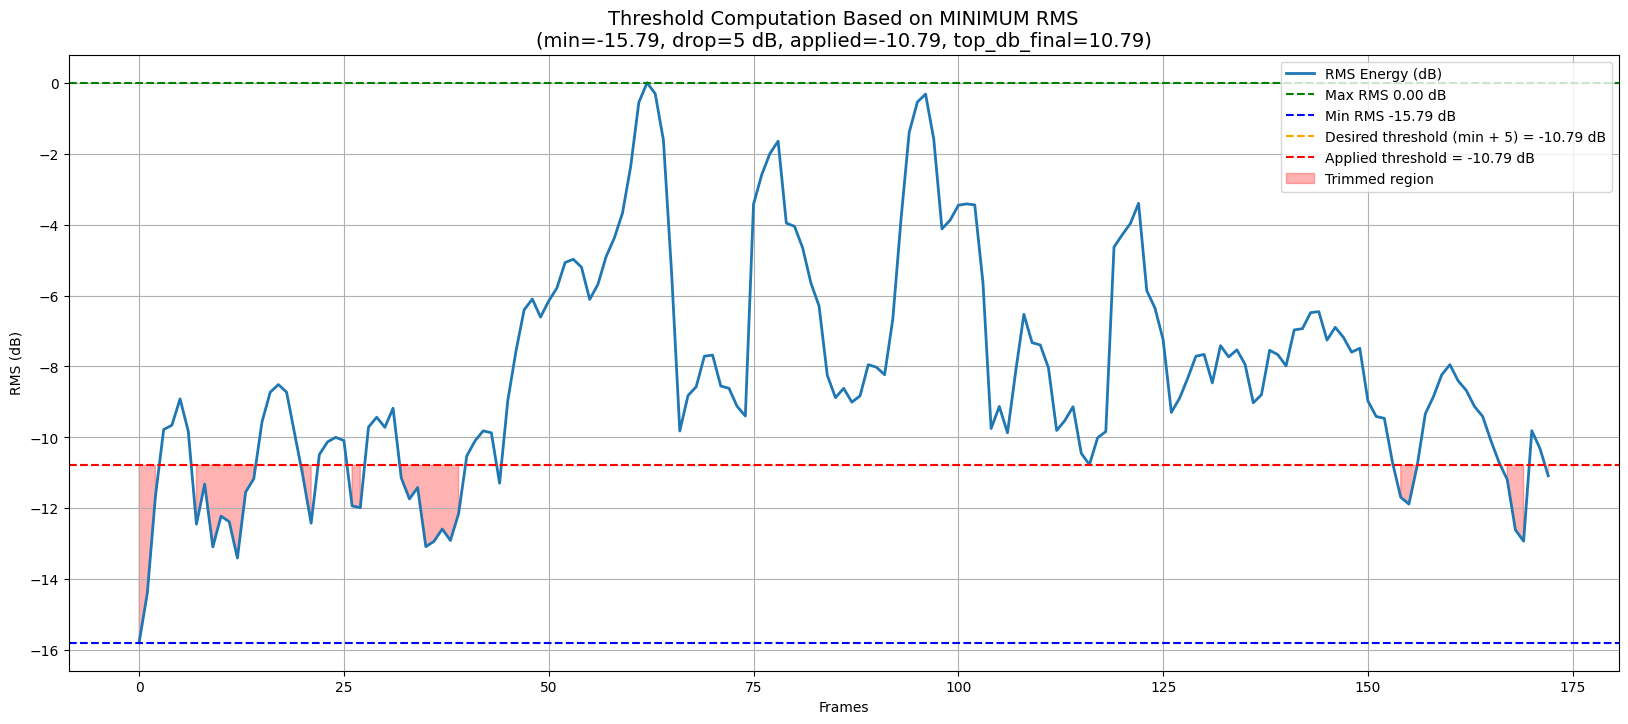

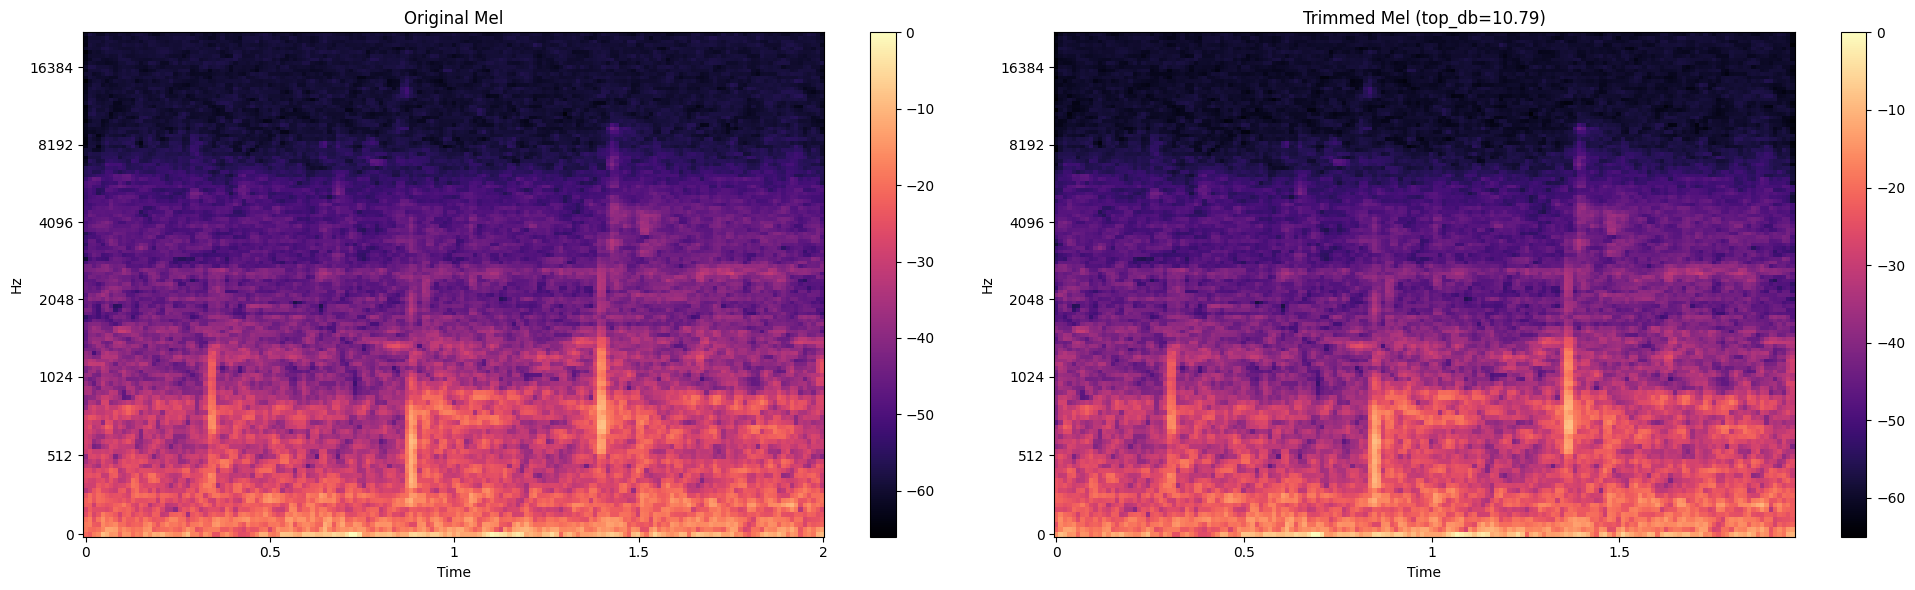

In [22]:
diagnostic_trim_dynamic(DROP_DB_DESEADO)

### Gaussian noise

In [ ]:
# PARAMETERS

MIN_AMP = 0.003    
MAX_AMP = 0.005   

In [ ]:
# DIAGNOSTIC

def diagnostic_gaussian_noise(min_amp, max_amp):
    print("\n========================================")
    print("          GAUSSIAN NOISE DIAGNOSTIC")
    print(f"     min_amplitude = {min_amp}")
    print(f"     max_amplitude = {max_amp}")
    print("========================================\n")

    # choose a random audio from the dataset
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}")

    y, sr = librosa.load(path, sr=None)

    # create Gaussian noise augmenter
    gns = AddGaussianNoise(
        min_amplitude=min_amp,
        max_amplitude=max_amp,
        p=1.0
    )

    # apply augmentation
    y_aug = gns(samples=y, sample_rate=sr)

    # create Mel-spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_aug = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    # visualization
    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("Original Mel")
    plt.colorbar()

    # Mel with Gaussian noise 
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(f"Mel with Gaussian Noise\n(min={min_amp}, max={max_amp})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


          GAUSSIAN NOISE DIAGNOSTIC
     min_amplitude = 0.003
     max_amplitude = 0.005

🎵 Selected audio: 035_15_P1.wav


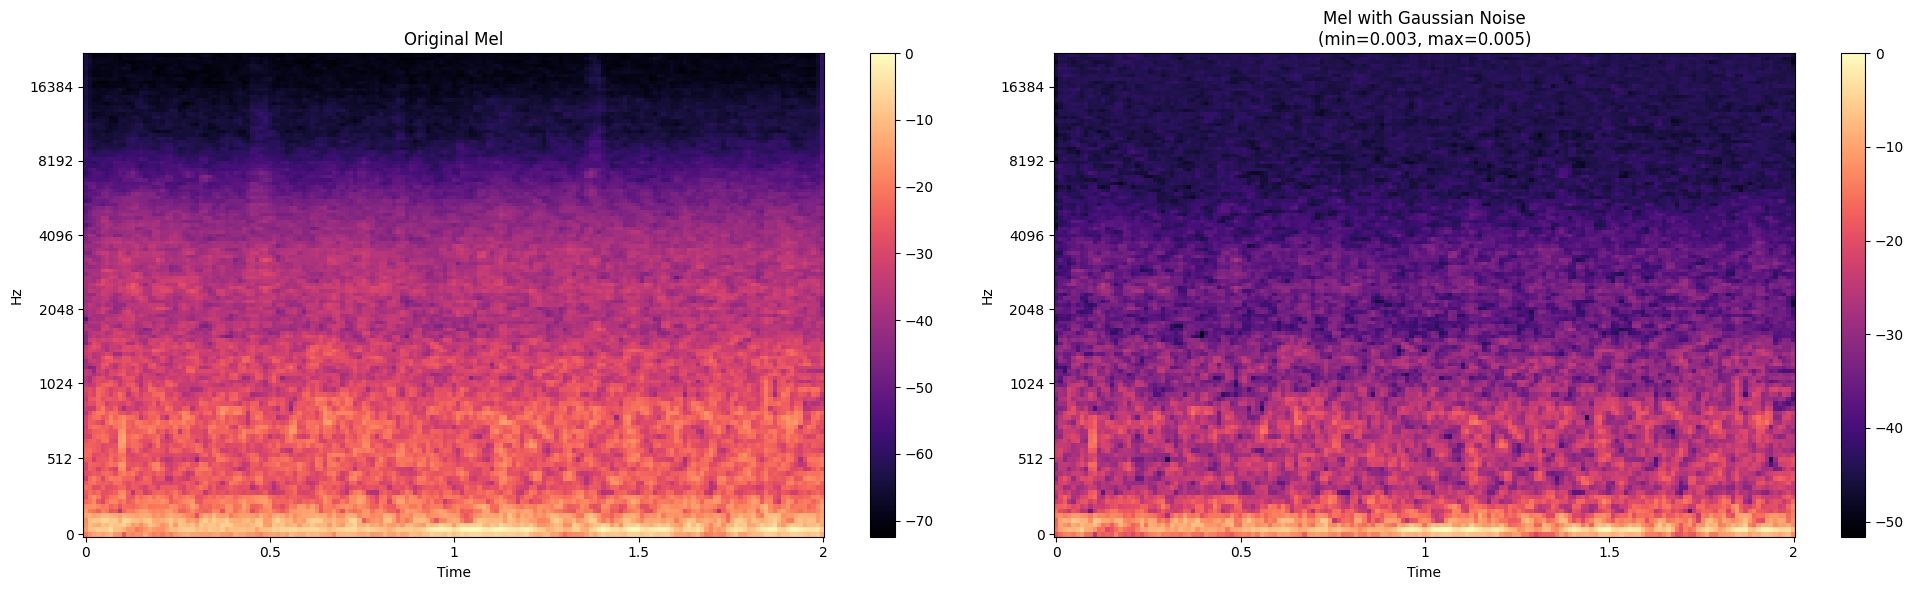

In [92]:
diagnostic_gaussian_noise(MIN_AMP, MAX_AMP)

# Shift Time


            TIME SHIFT DIAGNOSTIC
     TimeShiftRange = ±0.05 seconds

🎵 Selected audio: 089_49_P2.wav


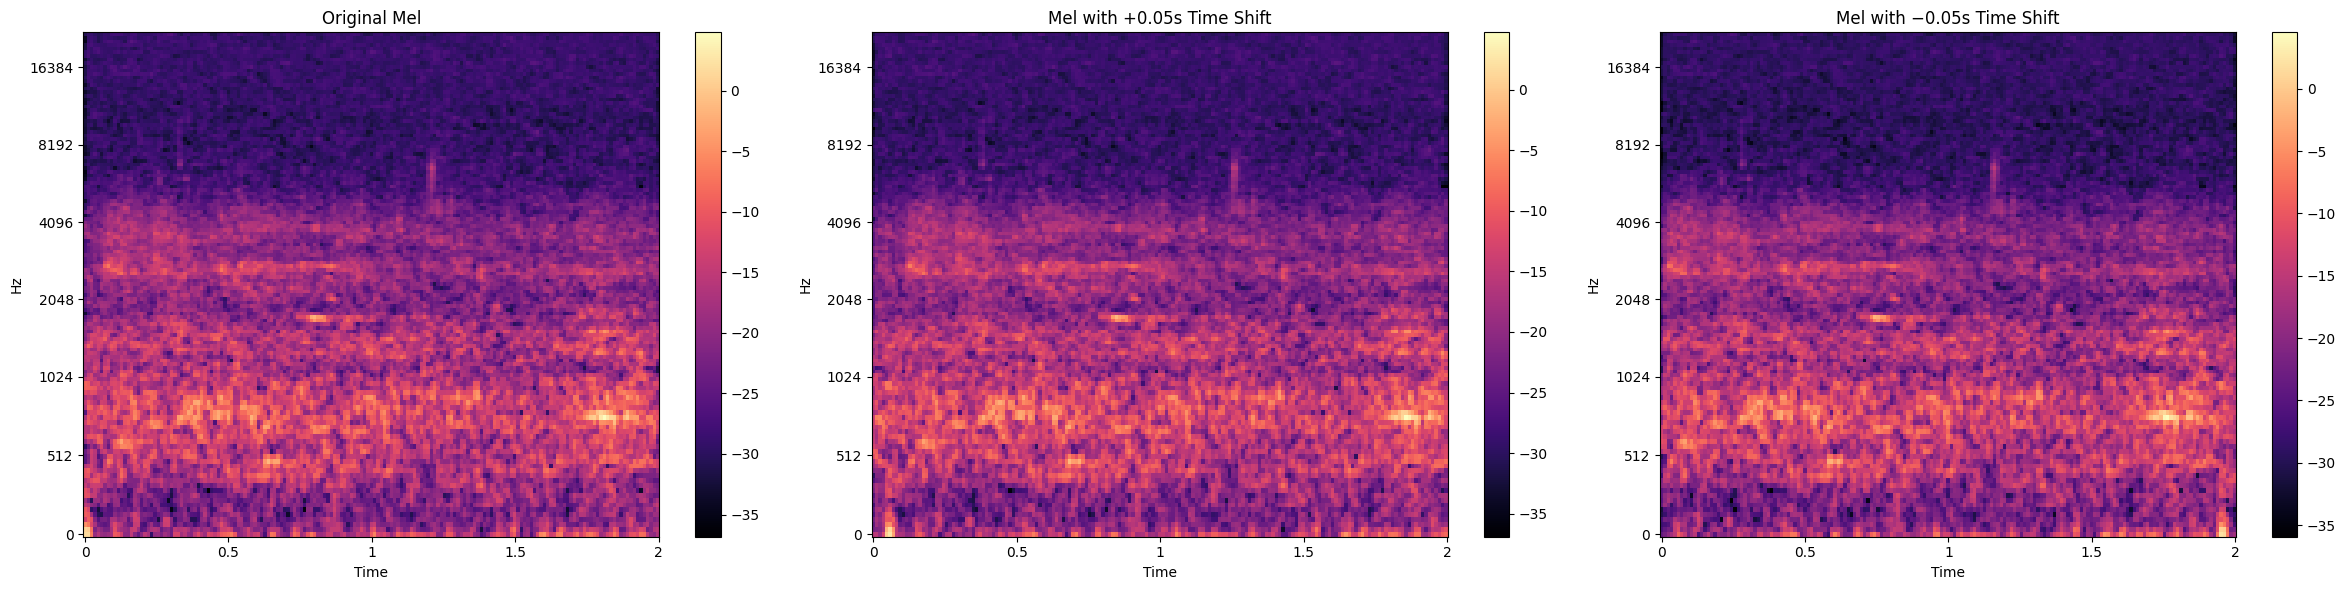

In [47]:
# =====================================================
# TIME SHIFT DIAGNOSTIC – CIRCULAR (NO BLACK AREAS)
# =====================================================

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

# ---------------------------
# PARAMETERS (DIAGNOSTIC)
# ---------------------------
TIME_SHIFT_SEC = 0.05   # exaggerated shift for VISUAL confirmation only

# ---------------------------
# CIRCULAR TIME SHIFT
# ---------------------------
def time_shift_circular(y, sr, shift_sec):
    shift = int(shift_sec * sr)
    if abs(shift) >= len(y):
        raise ValueError("Shift larger than signal length")
    return np.roll(y, shift)

# ---------------------------
# DIAGNOSTIC FUNCTION
# ---------------------------
def diagnostic_time_shift_circular(train_df, audio_dir, select_audio_fn, shift_sec):

    print("\n========================================")
    print("            TIME SHIFT DIAGNOSTIC")
    print(f"     TimeShiftRange = ±{shift_sec} seconds")
    print("========================================\n")

    # select random audio
    fname, path = select_audio_fn(train_df, audio_dir)
    print(f"🎵 Selected audio: {fname}")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # apply circular time shifts
    y_pos = time_shift_circular(y, sr, +shift_sec)
    y_neg = time_shift_circular(y, sr, -shift_sec)

    # Mel-spectrogram function (NO auto-normalization)
    def mel(y_):
        return librosa.power_to_db(
            librosa.feature.melspectrogram(y=y_, sr=sr),
            ref=1.0
        )

    mels = {
        "Original Mel": mel(y),
        f"Mel with +{shift_sec}s Time Shift": mel(y_pos),
        f"Mel with −{shift_sec}s Time Shift": mel(y_neg)
    }

    # visualization
    plt.figure(figsize=(24, 6))

    for i, (title, M) in enumerate(mels.items(), 1):
        plt.subplot(1, 3, i)
        librosa.display.specshow(
            M, sr=sr, x_axis="time", y_axis="mel", cmap="magma"
        )
        plt.title(title)
        plt.colorbar()

    plt.tight_layout()
    plt.show()

# ---------------------------
# RUN DIAGNOSTIC
# ---------------------------
diagnostic_time_shift_circular(
    train_df=train_df,
    audio_dir=ORG_AUDIO_DIR,
    select_audio_fn=select_audio_random,
    shift_sec=TIME_SHIFT_SEC
)

### Pink noise

In [ ]:
# PARAMETERS

MIN_SNR_DB = 16.0     
MAX_SNR_DB = 20.0     
F_DECAY = -3.01       

In [ ]:
# DIAGNOSTIC

def diagnostic_pink_noise(min_snr_db, max_snr_db, f_decay):
    print("\n========================================")
    print("            PINK NOISE DIAGNOSTIC")
    print(f"   min_snr_db = {min_snr_db}")
    print(f"   max_snr_db = {max_snr_db}")
    print(f"   f_decay    = {f_decay}")
    print("========================================\n")

    # choose a random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}")

    y, sr = librosa.load(path, sr=None)

    # create Pink Noise augmenter
    pn = AddColorNoise(
        min_snr_db=min_snr_db,
        max_snr_db=max_snr_db,
        min_f_decay=f_decay,
        max_f_decay=f_decay,
        p=1.0
    )

    # apply pink noise
    y_aug = pn(samples=y, sample_rate=sr)

    # create Mel-spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_aug = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    # visualization
    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # Mel with Pink Noise
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(f"Mel with PINK NOISE\n(min_snr={min_snr_db} | max_snr={max_snr_db})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


            PINK NOISE DIAGNOSTIC
   min_snr_db = 16.0
   max_snr_db = 20.0
   f_decay    = -3.01

🎵 Selected audio: 072_68_P2.wav


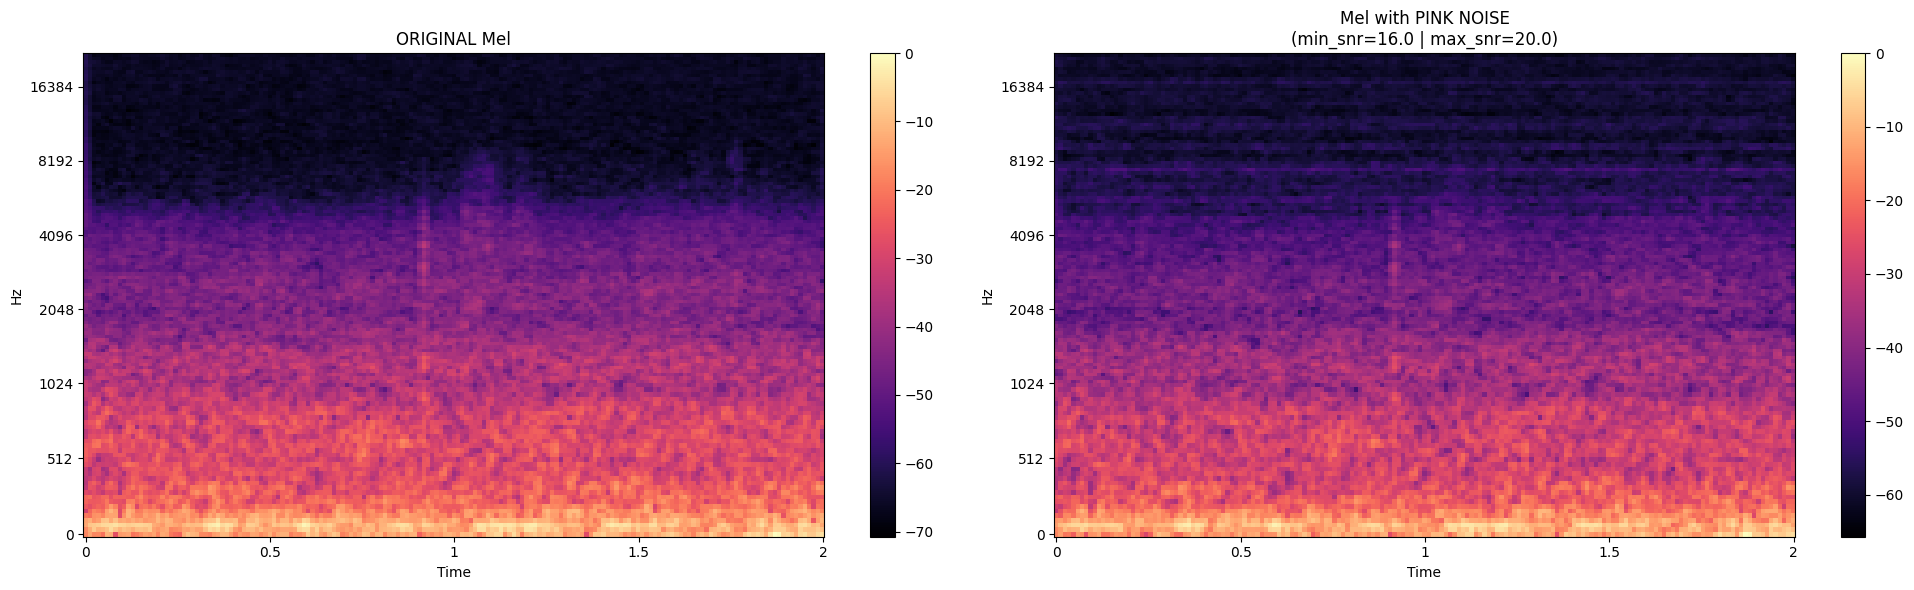

In [ ]:
diagnostic_pink_noise(MIN_SNR_DB, MAX_SNR_DB, F_DECAY)

### Loudness

In [ ]:
# PARAMETERS
MIN_LUFS = -100.0   
MAX_LUFS = -90.0      

In [ ]:
# DIAGNOSTIC

def diagnostic_loudness(min_lufs, max_lufs):
    print("\n========================================")
    print("        LOUDNESS NORMALIZATION DIAGNOSTIC")
    print(f"   min_lufs = {min_lufs}")
    print(f"   max_lufs = {max_lufs}")
    print("========================================\n")

    # choose a random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}")

    y, sr = librosa.load(path, sr=None)

    # create LoudnessNormalization augmenter
    ln = LoudnessNormalization(
        min_lufs=min_lufs,
        max_lufs=max_lufs,
        p=1.0
    )

    # apply LoudnessNormalization
    y_aug = ln(samples=y, sample_rate=sr)

    # create Mel-spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_aug = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    # visualization
    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # Mel with Loudness Normalization
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(f"Mel with LOUDNESS NORMALIZATION\n(min={min_lufs} LUFS | max={max_lufs} LUFS)")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


        LOUDNESS NORMALIZATION DIAGNOSTIC
   min_lufs = -100.0
   max_lufs = -90.0

🎵 Selected audio: 102_35_P2.wav


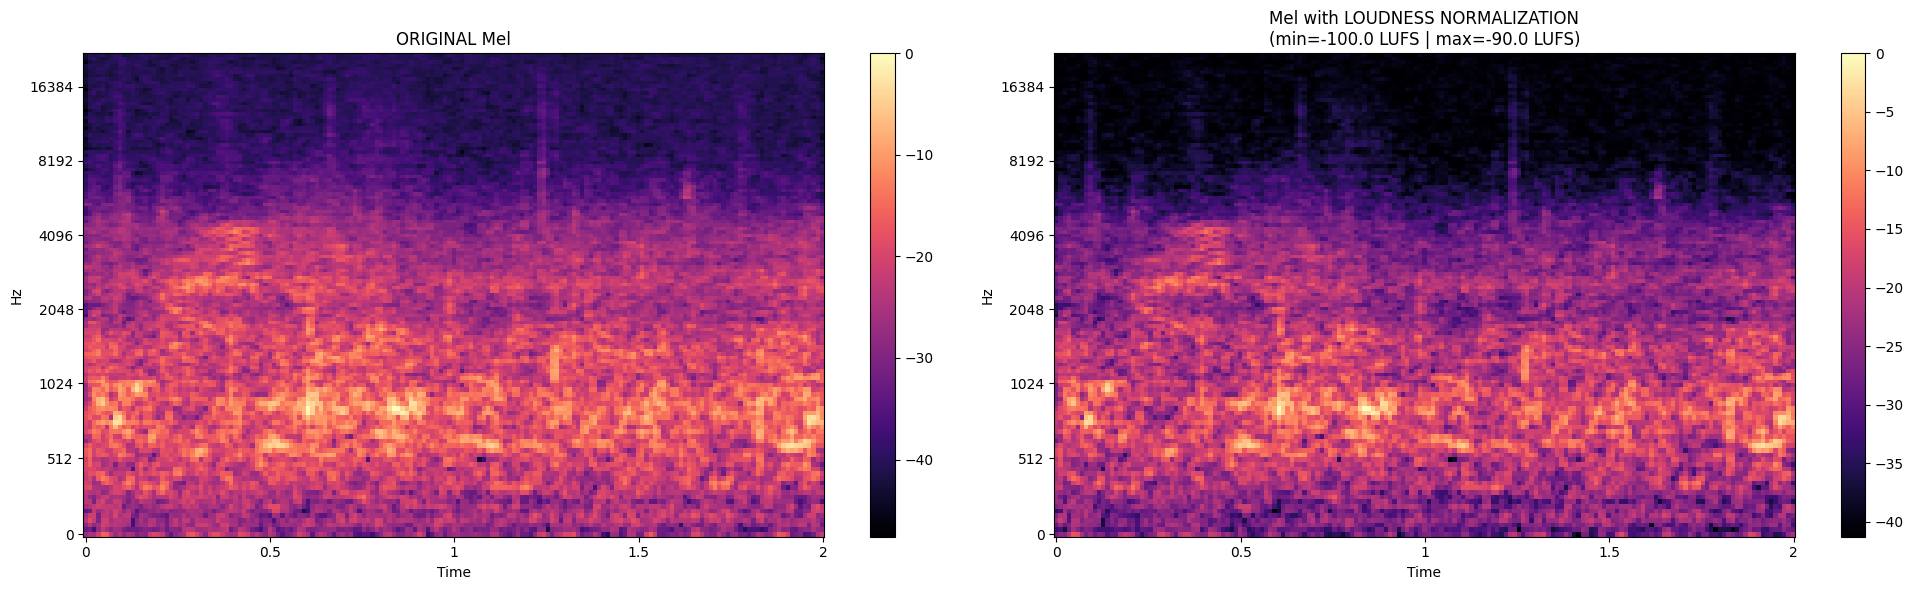

In [97]:
diagnostic_loudness(MIN_LUFS, MAX_LUFS)

### Distortion

In [ ]:
# PARAMETERS

MIN_DISTORT = 0.6      
MAX_DISTORT = 0.8     

In [ ]:
# DIAGNOSTIC

def diagnostic_tanh(min_d, max_d):
    print("\n========================================")
    print("           TANH DISTORTION DIAGNOSTIC")
    print(f"   min_distortion = {min_d}")
    print(f"   max_distortion = {max_d}")
    print("========================================\n")

    # choose a random audio from the dataset
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}")

    y, sr = librosa.load(path, sr=None)

    # create TanhDistortion augmenter
    td = TanhDistortion(
        min_distortion=min_d,
        max_distortion=max_d,
        p=1.0
    )

    # apply distortion
    y_aug = td(samples=y, sample_rate=sr)

    # create Mel-spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_aug = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    # visualization
    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # Mel with TanhDistortion
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(f"Mel with TANH DISTORTION\n(min={min_d} | max={max_d})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


           TANH DISTORTION DIAGNOSTIC
   min_distortion = 0.6
   max_distortion = 0.8

🎵 Selected audio: 030_88_P2.wav


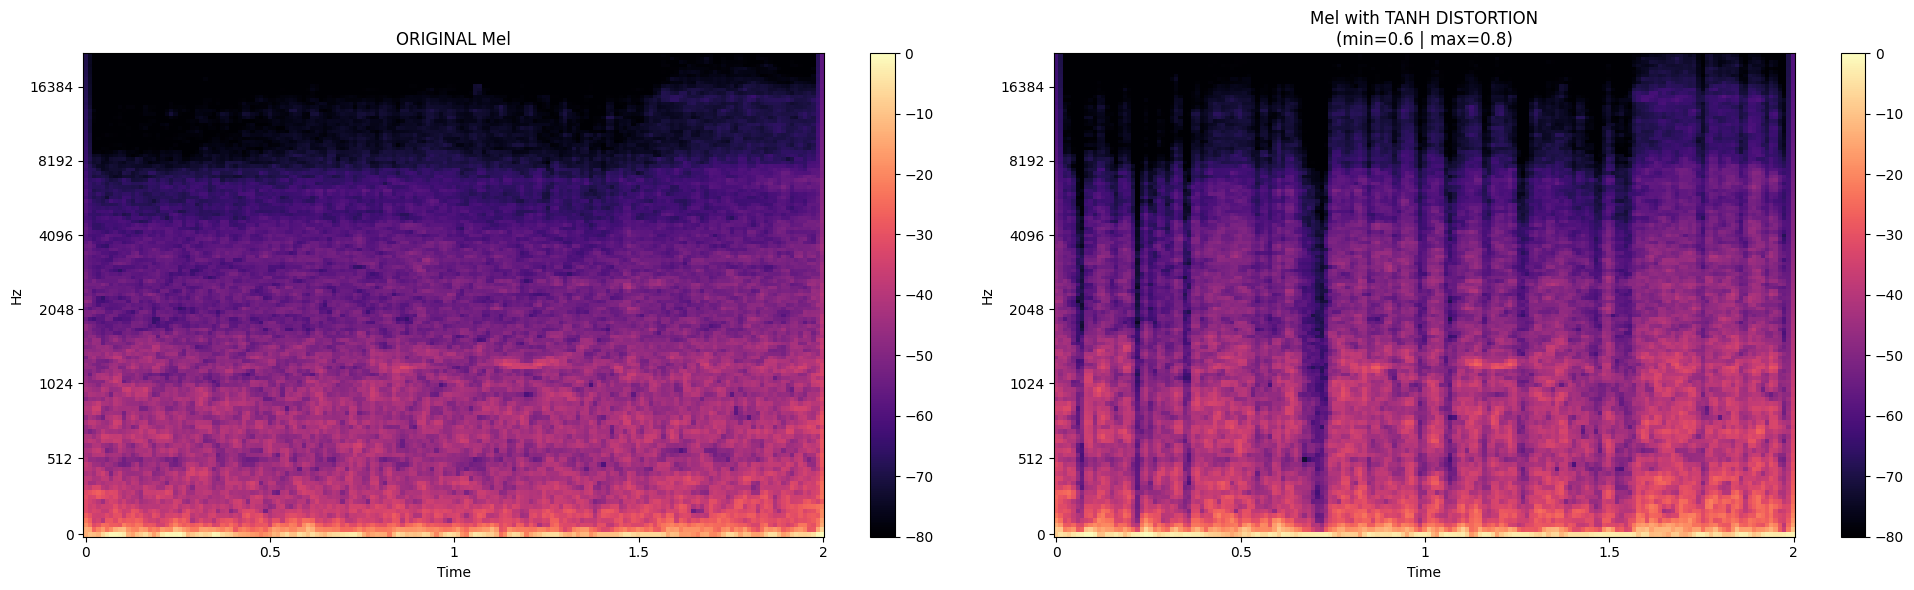

In [101]:
diagnostic_tanh(MIN_DISTORT, MAX_DISTORT)

### Simple delay

In [ ]:
# PARAMETERS

DELAY_MS = 100       # recomended: 20–200 ms
DECAY = 0.8          # recomended 0.1–0.8

In [ ]:
# FUNCTION

def apply_delay(y, sr, delay_ms=50, decay=0.4):
    """
    Applies a simple delay (echo): audio + delayed audio * decay
    """
    delay_samples = int(sr * (delay_ms / 1000.0))

    # create buffer with space for delay
    y_out = np.zeros(len(y) + delay_samples, dtype=np.float32)

    # original signal
    y_out[:len(y)] += y

    # delayed signal
    y_out[delay_samples:] += y * decay

    return y_out


# DIAGNOSTIC

def diagnostic_delay(delay_ms, decay):
    print("\n========================================")
    print("           TIME DELAY DIAGNOSTIC")
    print(f"   delay_ms = {delay_ms} ms")
    print(f"   decay    = {decay}")
    print("========================================\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # apply delay
    y_aug = apply_delay(y, sr, delay_ms, decay)

    # create Mel-spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_aug = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    # TRIM-style visualization
    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap="magma")
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # Mel with delay
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis='time', y_axis='mel', cmap="magma")
    plt.title(f"Mel with TIME DELAY\n({delay_ms} ms | decay={decay})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


           TIME DELAY DIAGNOSTIC
   delay_ms = 100 ms
   decay    = 0.8

🎵 Selected audio: 022_46_P2.wav


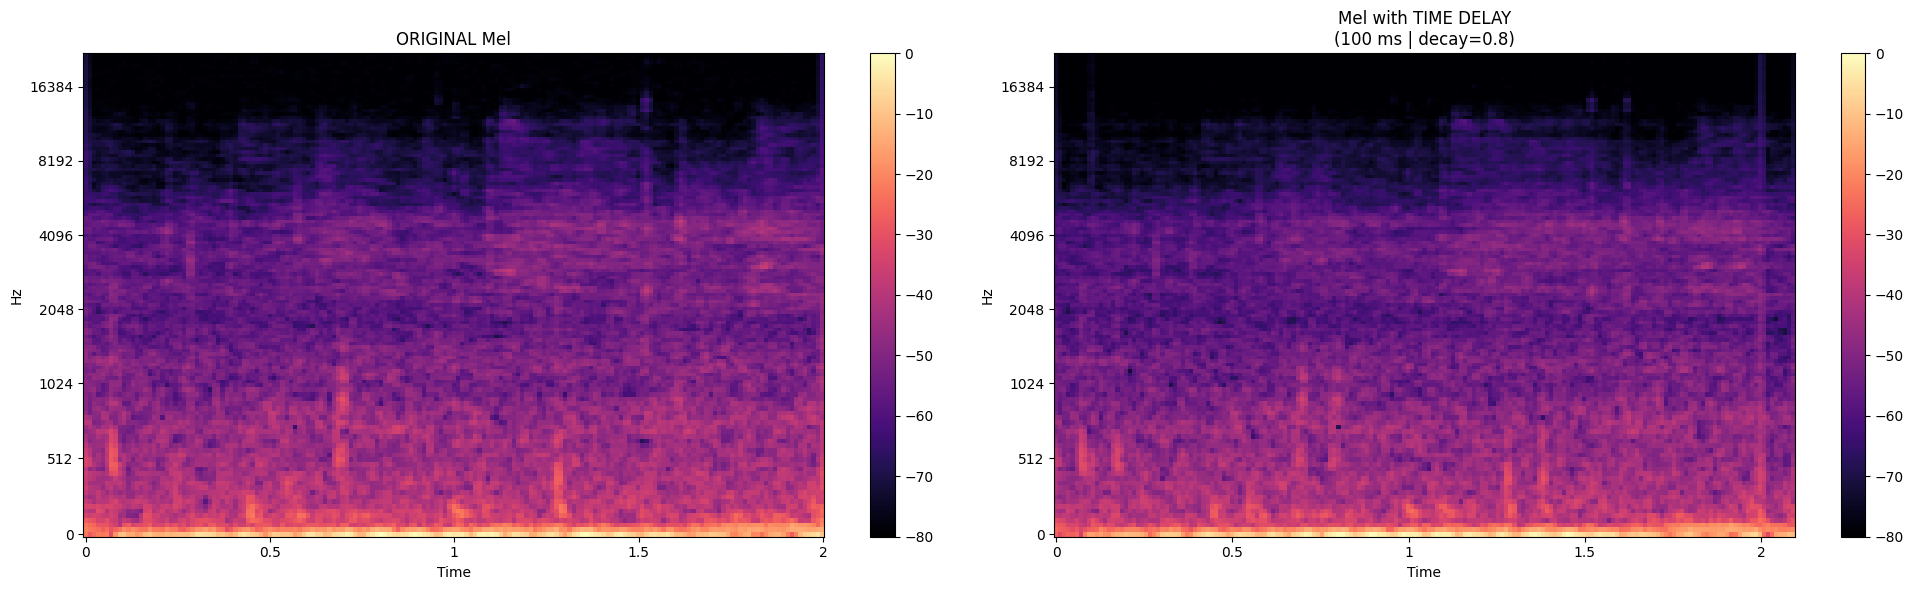

In [104]:
diagnostic_delay(DELAY_MS, DECAY)

### Reverb

In [ ]:
# PARAMETERS

DECAY_TIME = 0.2       # 0.2–0.8 recommended
PRE_DELAY_MS = 10       # 0–40 recommended
WET_LEVEL = 0.2         # 0.1–0.35 recommended

In [ ]:
# FUNCTION TO GENERATE SYNTHETIC IR

def generate_ir(sr, decay_time=0.4, pre_delay_ms=20):
    """
    Controlled exponential synthetic IR.
    decay_time: tail duration (seconds)
    pre_delay_ms: delay before reverb starts
    """
    ir_length = int(sr * decay_time)
    t = np.linspace(0, decay_time, ir_length)

    # exponential decay
    ir = np.exp(-3 * t / decay_time)

    ir = ir / np.max(np.abs(ir))  # normalize

    pre_delay_samples = int(sr * (pre_delay_ms / 1000))
    ir = np.concatenate([np.zeros(pre_delay_samples), ir])

    return ir.astype(np.float32)


# FUNCTION TO APPLY REVERB

def apply_reverb(y, sr, decay_time=0.4, pre_delay_ms=20, wet_level=0.3):
    """
    Convolution-style reverb using synthetic IR.
    Very safe if parameters are kept low.
    """
    ir = generate_ir(sr, decay_time, pre_delay_ms)

    # efficient convolution
    y_reverb = np.convolve(y, ir, mode="full")
    y_reverb = y_reverb[:len(y)]  # same length

    # dry/wet mix
    y_out = (1 - wet_level) * y + wet_level * y_reverb

    # normalize if needed
    maxv = np.max(np.abs(y_out))
    if maxv > 0.99:
        y_out = y_out / maxv

    return y_out.astype(np.float32)


# DIAGNOSTIC

def playback_reverb(decay_time, pre_delay_ms, wet_level):
    print("\n========================================")
    print("       AUDIO PLAYBACK — REVERB")
    print("----------------------------------------")
    print(f" decay_time   = {decay_time} s")
    print(f" pre_delay_ms = {pre_delay_ms} ms")
    print(f" wet_level    = {wet_level}")
    print("========================================\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load original audio
    y, sr = librosa.load(path, sr=None)

    # create reverb version
    y_aug = apply_reverb(y, sr, decay_time, pre_delay_ms, wet_level)

    # playback
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    print("\n🔊 AUDIO WITH REVERB:")
    display(Audio(data=y_aug, rate=sr))

    # visualization
    mel_orig = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr), ref=np.max)
    mel_aug  = librosa.power_to_db(librosa.feature.melspectrogram(y=y_aug, sr=sr), ref=np.max)

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(f"Mel with REVERB\n(decay={decay_time}s | pre={pre_delay_ms}ms | wet={wet_level})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()



       AUDIO PLAYBACK — REVERB
----------------------------------------
 decay_time   = 0.2 s
 pre_delay_ms = 10 ms
 wet_level    = 0.2

🎵 Selected audio: 029_67_P1.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH REVERB:


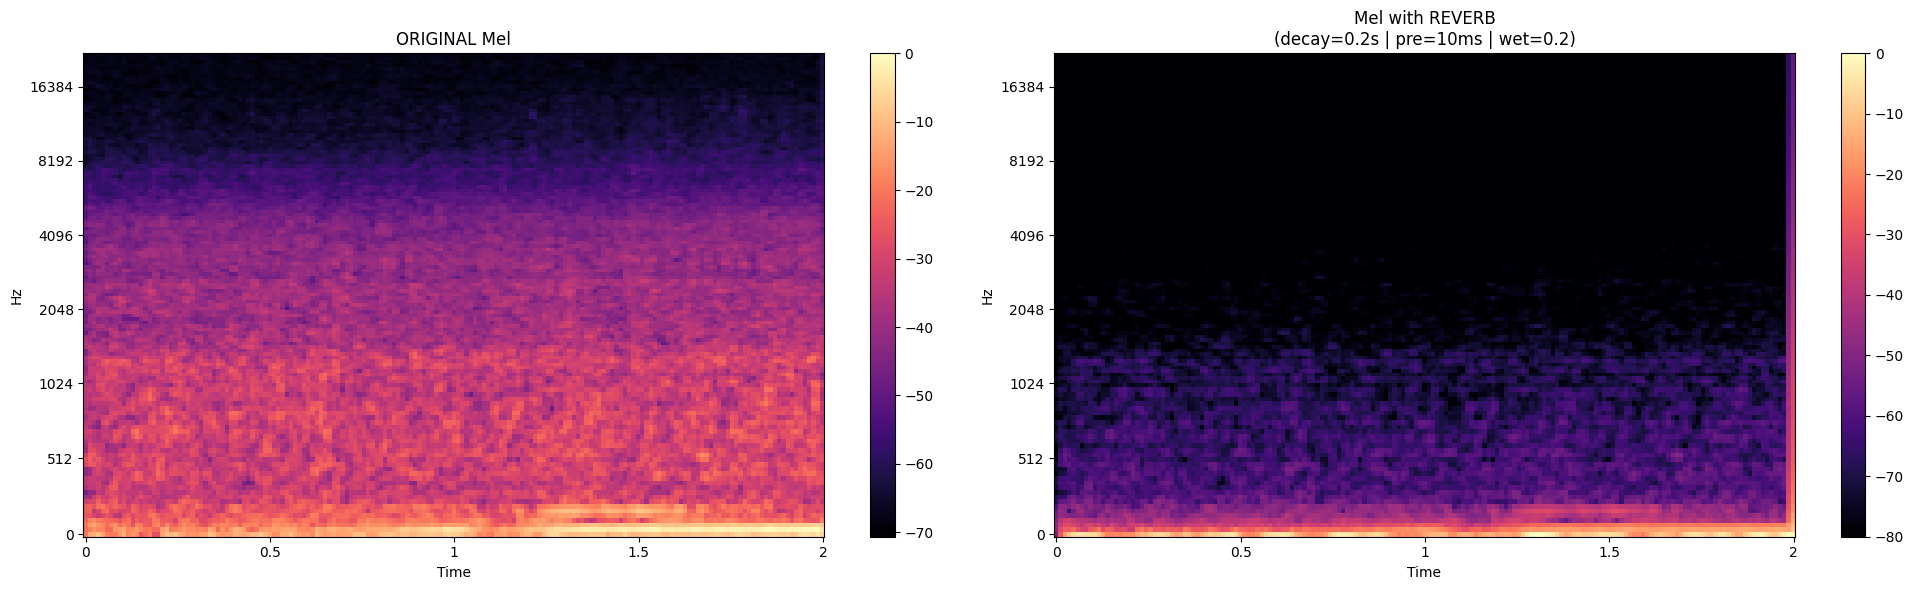

In [27]:
playback_reverb(DECAY_TIME, PRE_DELAY_MS, WET_LEVEL)

In [ ]:
# PARAMETERS

ROOM_SIZE = 0.25    # ≈ decay (0.1–0.7 recommended)
WET_LEVEL = 0.5     # 0.1–0.35 recommended
DRY_LEVEL = 0.5     # usually 0.7–1.0


   AUDIO PLAYBACK — REVERB (Pedalboard)
----------------------------------------
 room_size = 0.25
 wet_level = 0.5
 dry_level = 0.5

🎵 Selected audio: 038_13_P1.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH REVERB:


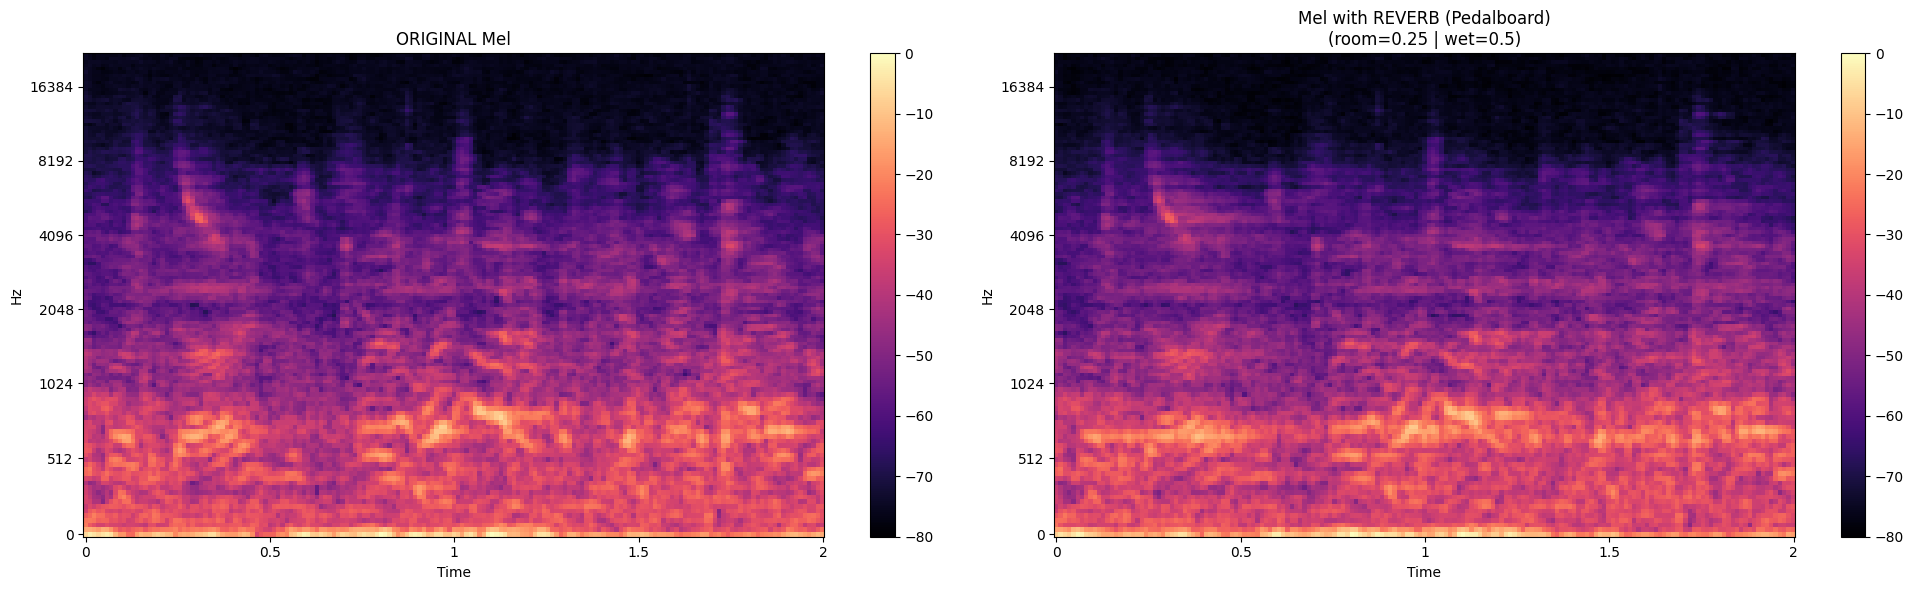

In [ ]:
# DIAGNOSTIC

def playback_reverb_pedalboard(room_size, wet_level, dry_level):
    print("\n========================================")
    print("   AUDIO PLAYBACK — REVERB (Pedalboard)")
    print("----------------------------------------")
    print(f" room_size = {room_size}")
    print(f" wet_level = {wet_level}")
    print(f" dry_level = {dry_level}")
    print("========================================\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(path, sr=None, mono=True)

    # reverb effect
    board = Pedalboard([
        Reverb(
            room_size=room_size,
            wet_level=wet_level,
            dry_level=dry_level
        )
    ])

    # apply reverb
    y_aug = board(y, sr)

    # playback
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    print("\n🔊 AUDIO WITH REVERB:")
    display(Audio(data=y_aug, rate=sr))

    # Mel spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_aug = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis="time", y_axis="mel", cmap="magma")
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_aug, sr=sr, x_axis="time", y_axis="mel", cmap="magma")
    plt.title(
        f"Mel with REVERB (Pedalboard)\n"
        f"(room={room_size} | wet={wet_level})"
    )
    plt.colorbar()

    plt.tight_layout()
    plt.show()


playback_reverb_pedalboard(ROOM_SIZE, WET_LEVEL, DRY_LEVEL)

### Additive white gaussian noise

In [ ]:
# PARAMETER

AWN_MIN_AMP = 0.002      # recommended: 0.0005 – 0.005
AWN_MAX_AMP = 0.005      # higher → more noise
AWN_P       = 1.0        # probability

In [ ]:
# DIAGNOSTIC

def diagnostic_awn(min_amp, max_amp, p):
    print("\n========================================")
    print("         ADDITIVE WHITE NOISE DIAGNOSTIC")
    print("========================================")
    print(f" min_amplitude = {min_amp}")
    print(f" max_amplitude = {max_amp}")
    print(f" probability   = {p}")
    print("----------------------------------------\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # create AWN augmenter (explicit parameters)
    awn_aug = AddGaussianNoise(
        min_amplitude=min_amp,
        max_amplitude=max_amp,
        p=p
    )

    # apply AWN
    y_aug = awn_aug(samples=y, sample_rate=sr)

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    # augmented audio
    print("\n🔊 AUDIO WITH ADDITIVE WHITE NOISE:")
    display(Audio(data=y_aug, rate=sr))

    # Mel-spectrograms
    mel_orig = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_awn = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr),
        ref=np.max
    )

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_orig, sr=sr, x_axis='time', y_axis='mel', cmap="magma")
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_awn, sr=sr, x_axis='time', y_axis='mel', cmap="magma")
    plt.title(f"Mel with AWN\n(min={min_amp} | max={max_amp} | p={p})")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


         ADDITIVE WHITE NOISE DIAGNOSTIC
 min_amplitude = 0.002
 max_amplitude = 0.005
 probability   = 1.0
----------------------------------------

🎵 Selected audio: 003_24_P1.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH ADDITIVE WHITE NOISE:


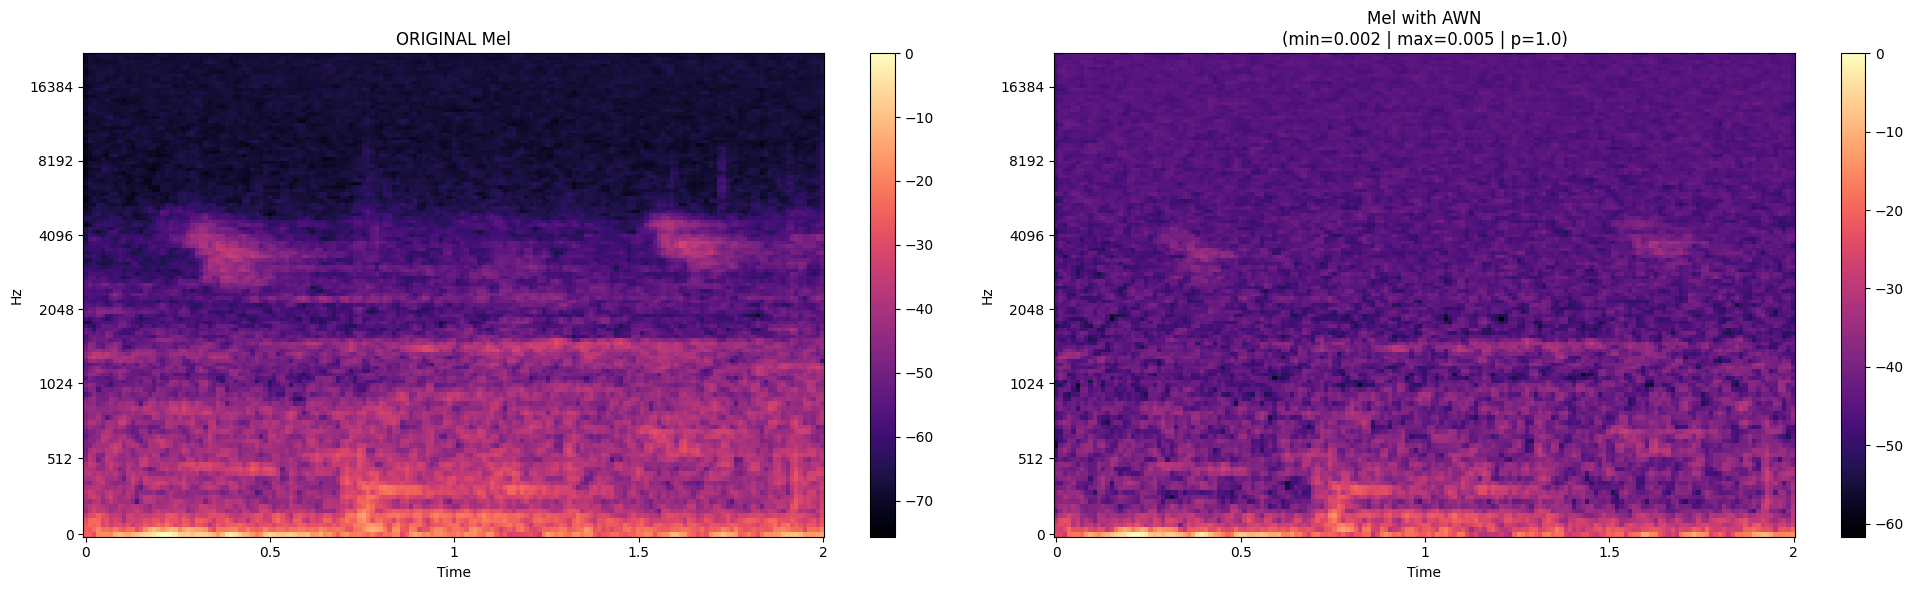

In [30]:
diagnostic_awn(AWN_MIN_AMP, AWN_MAX_AMP, AWN_P)

### Limiter

In [8]:
# PARAMETERS

LMT_MIN_THR_DB = -12.0      # lower threshold (softer)
LMT_MAX_THR_DB = -6.0       # higher threshold (more aggressive)
LMT_MIN_ATTACK  = 0.001     # minimum attack (seconds)
LMT_MAX_ATTACK  = 0.01      # maximum attack
LMT_MIN_RELEASE = 0.05      # minimum release
LMT_MAX_RELEASE = 0.2       # maximum release
LMT_P           = 1.0       # always apply during diagnostic

In [ ]:
# DIAGNOSTIC
def diagnostic_lmt_auto(min_thr_db, max_thr_db,
                        min_attack, max_attack,
                        min_release, max_release,
                        p):
    print("\n========================================")
    print("         LIMITER (AUTO) DIAGNOSTIC")
    print("========================================")
    print(f" threshold (dB) = {min_thr_db} → {max_thr_db}")
    print(f" attack         = {min_attack}s → {max_attack}s")
    print(f" release        = {min_release}s → {max_release}s")
    print(" mode           = relative_to_signal_peak")
    print("----------------------------------------\n")

    # select random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # measure signal peak
    peak = np.max(np.abs(y))
    print(f"🔎 Signal peak: {peak:.4f}")

    # create limiter
    limiter = Limiter(
        min_threshold_db=min_thr_db,
        max_threshold_db=max_thr_db,
        min_attack=min_attack,
        max_attack=max_attack,
        min_release=min_release,
        max_release=max_release,
        threshold_mode="relative_to_signal_peak",
        p=p
    )

    # apply limiter
    y_aug = limiter(samples=y, sample_rate=sr)

    # original audio
    print("\n🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    # limited audio
    print("\n🔊 LIMITED AUDIO (AUTO):")
    display(Audio(data=y_aug, rate=sr))

    # Mel spectrograms
    mel_o = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr), ref=np.max)
    mel_l = librosa.power_to_db(librosa.feature.melspectrogram(y=y_aug, sr=sr), ref=np.max)

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap="magma")
    plt.title("ORIGINAL")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_l, sr=sr, x_axis='time', y_axis='mel', cmap="magma")
    plt.title("LIMITED (AUTO)")
    plt.colorbar()

    plt.tight_layout()
    plt.show()



         LIMITER (AUTO) DIAGNOSTIC
 threshold (dB) = -12.0 → -6.0
 attack         = 0.001s → 0.01s
 release        = 0.05s → 0.2s
 mode           = relative_to_signal_peak
----------------------------------------

🎵 Selected audio: 025_71_P1.wav

🔎 Signal peak: 0.0383

🔊 ORIGINAL AUDIO:



🔊 LIMITED AUDIO (AUTO):


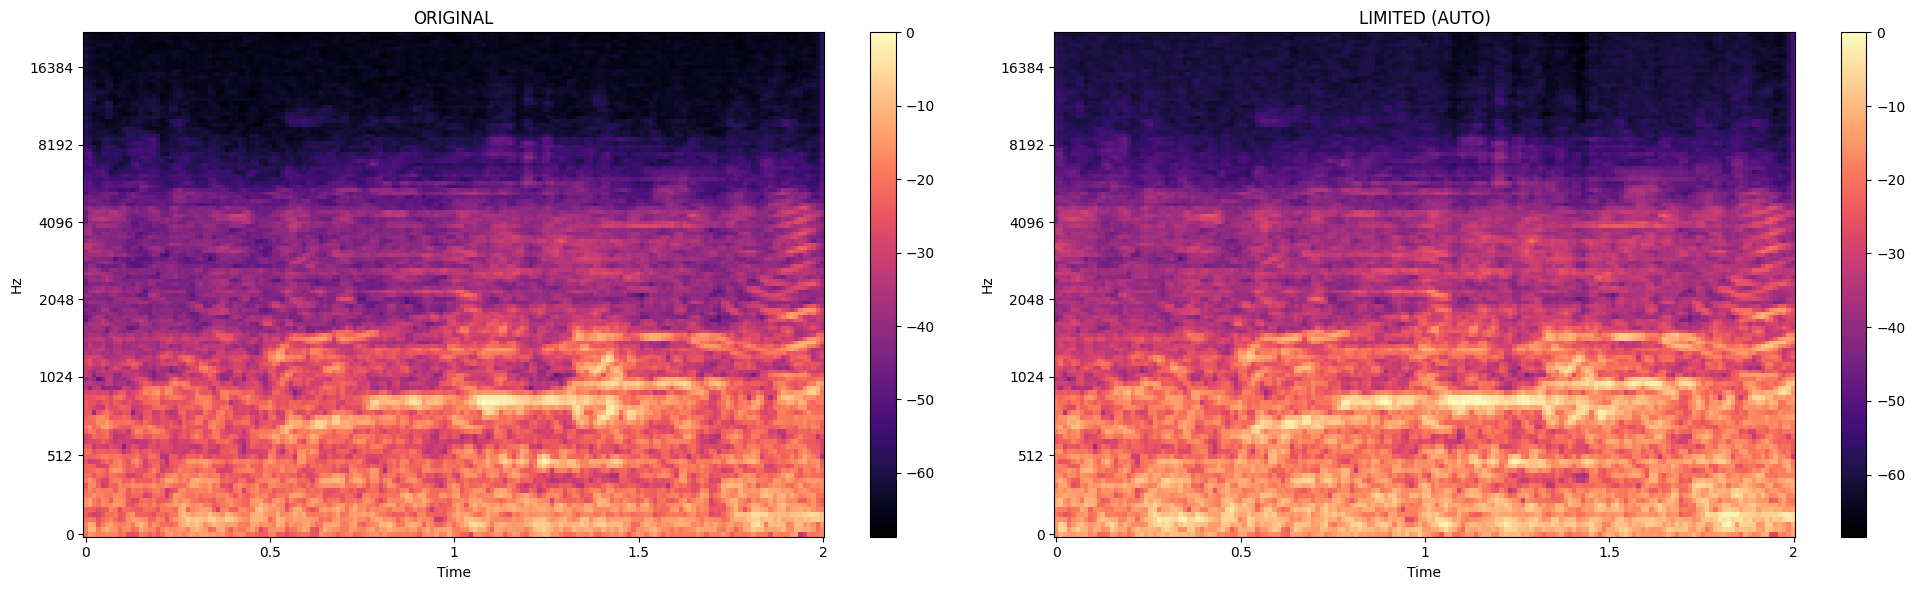

In [13]:
diagnostic_lmt_auto(
    LMT_MIN_THR_DB,
    LMT_MAX_THR_DB,
    LMT_MIN_ATTACK,
    LMT_MAX_ATTACK,
    LMT_MIN_RELEASE,
    LMT_MAX_RELEASE,
    LMT_P
)

### High-shelf filter

In [ ]:
# PARAMETERS

HS_MIN_CENTER = 2000.0      # minimum shelf frequency (Hz)
HS_MAX_CENTER = 8000.0      # maximum shelf frequency (Hz)
HS_MIN_GAIN   = 15.0        # minimum gain in dB
HS_MAX_GAIN   = 20.0        # maximum gain in dB
HS_MIN_Q      = 0.8         # minimum Q
HS_MAX_Q      = 0.8         # maximum Q
HS_P          = 1.0         # always apply during diagnostic

In [ ]:
# DIAGNOSTIC

def diagnostic_eq_highshelf(min_center, max_center,
                            min_gain,   max_gain,
                            min_q,      max_q,
                            p):

    print("\n========================================")
    print("           HIGH‑SHELF EQ DIAGNOSTIC")
    print("========================================")
    print(f" Center freq (Hz): {min_center} → {max_center}")
    print(f" Gain (dB)       : {min_gain} → {max_gain}")
    print(f" Q factor        : {min_q} → {max_q}")
    print(f" Probability (p) : {p}")
    print("----------------------------------------\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # create High‑Shelf
    hsh = HighShelfFilter(
        min_center_freq=min_center,
        max_center_freq=max_center,
        min_gain_db=min_gain,
        max_gain_db=max_gain,
        min_q=min_q,
        max_q=max_q,
        p=p
    )

    # apply effect
    y_aug = hsh(samples=y, sample_rate=sr)

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    # processed audio
    print("\n🔊 AUDIO WITH HIGH‑SHELF (RANGE-BASED):")
    display(Audio(data=y_aug, rate=sr))

    # Mel spectrograms
    mel_o = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y,     sr=sr), ref=np.max
    )
    mel_h = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr), ref=np.max
    )

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # high-shelf
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_h, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(
        f"Mel with HIGH‑SHELF (RANGE)\n"
        f"{min_gain}–{max_gain} dB @ {min_center}–{max_center} Hz\n"
        f"Q={min_q}–{max_q}"
    )
    plt.colorbar()

    plt.tight_layout()
    plt.show()


           HIGH‑SHELF EQ DIAGNOSTIC
 Center freq (Hz): 2000.0 → 8000.0
 Gain (dB)       : 15.0 → 20.0
 Q factor        : 0.8 → 0.8
 Probability (p) : 1.0
----------------------------------------

🎵 Selected audio: 059_22_P2.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH HIGH‑SHELF (RANGE-BASED):


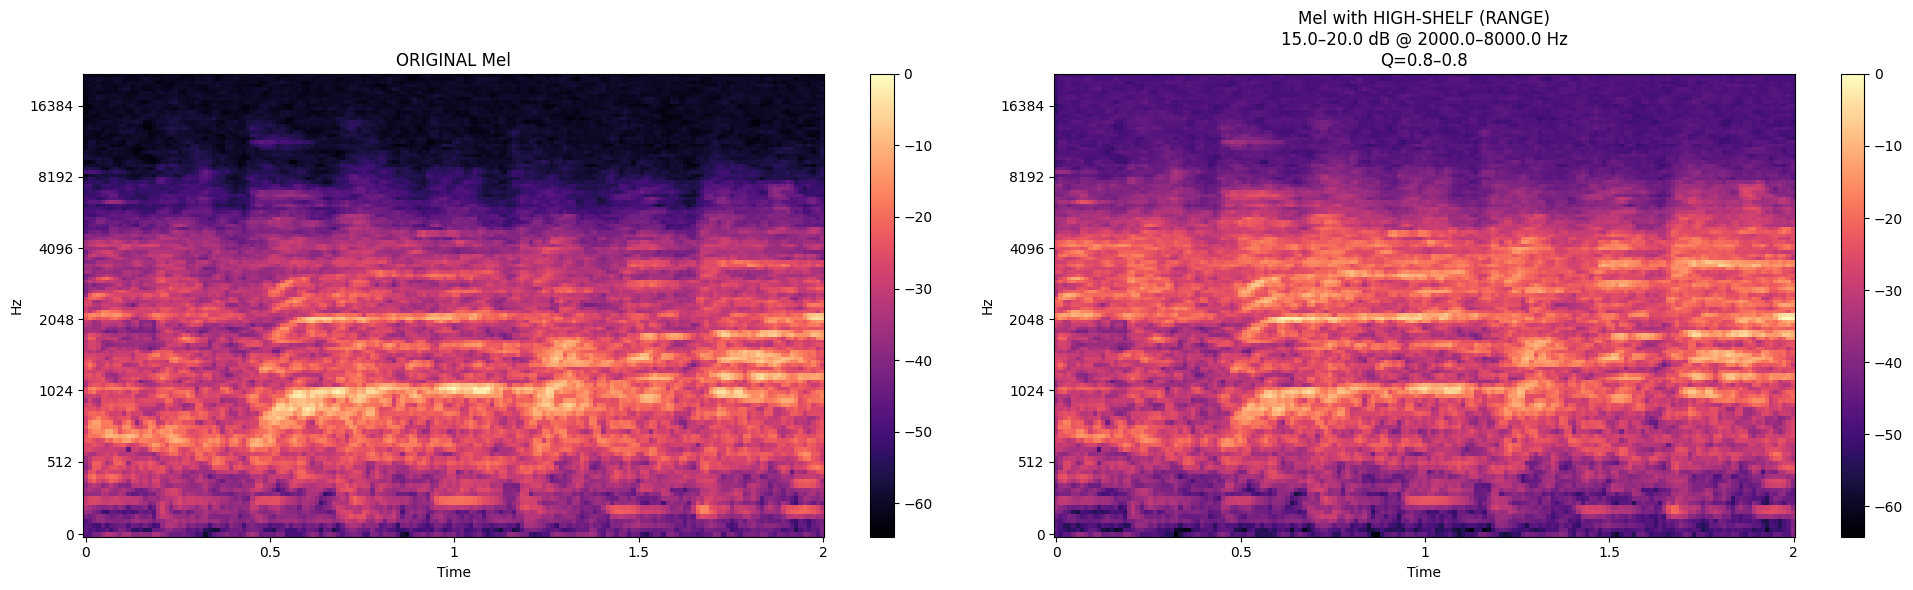

In [167]:
diagnostic_eq_highshelf(
    HS_MIN_CENTER,
    HS_MAX_CENTER,
    HS_MIN_GAIN,
    HS_MAX_GAIN,
    HS_MIN_Q,
    HS_MAX_Q,
    HS_P
)

### Low-shelf filter

In [ ]:
# PARAMETERS

LS_MIN_CENTER = 50.0        # minimum shelf frequency (Hz)
LS_MAX_CENTER = 500.0       # maximum shelf frequency (Hz)
LS_MIN_GAIN   = 15.0        # minimum gain in dB
LS_MAX_GAIN   = 20.0        # maximum gain in dB
LS_MIN_Q      = 0.7         # minimum Q
LS_MAX_Q      = 0.7         # maximum Q
LS_P          = 1.0         # always apply during diagnostic

In [ ]:
# DIAGNOSTIC

def diagnostic_eq_lowshelf(min_center, max_center,
                           min_gain,   max_gain,
                           min_q,      max_q,
                           p):

    print("\n========================================")
    print("              LOW‑SHELF EQ DIAGNOSTIC")
    print("========================================")
    print(f" Center freq (Hz): {min_center} → {max_center}")
    print(f" Gain (dB)       : {min_gain} → {max_gain}")
    print(f" Q factor        : {min_q} → {max_q}")
    print(f" Probability (p) : {p}")
    print("----------------------------------------\n")

    # choose random audio
    fname, path = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(path, sr=None)

    # create Low‑Shelf
    lsh = LowShelfFilter(
        min_center_freq=min_center,
        max_center_freq=max_center,
        min_gain_db=min_gain,
        max_gain_db=max_gain,
        min_q=min_q,
        max_q=max_q,
        p=p
    )

    # apply effect
    y_aug = lsh(samples=y, sample_rate=sr)

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    # processed audio
    print("\n🔊 AUDIO WITH LOW‑SHELF (RANGE-BASED):")
    display(Audio(data=y_aug, rate=sr))

    # Mel spectrograms
    mel_o = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y,     sr=sr), ref=np.max
    )
    mel_l = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_aug, sr=sr), ref=np.max
    )

    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # low‑Shelf Mel
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_l, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(
        f"Mel with LOW‑SHELF (RANGE)\n"
        f"{min_gain}–{max_gain} dB @ {min_center}–{max_center} Hz\n"
        f"Q={min_q}–{max_q}"
    )
    plt.colorbar()

    plt.tight_layout()
    plt.show()



              LOW‑SHELF EQ DIAGNOSTIC
 Center freq (Hz): 50.0 → 500.0
 Gain (dB)       : 15.0 → 20.0
 Q factor        : 0.7 → 0.7
 Probability (p) : 1.0
----------------------------------------

🎵 Selected audio: 063_42_P2.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH LOW‑SHELF (RANGE-BASED):


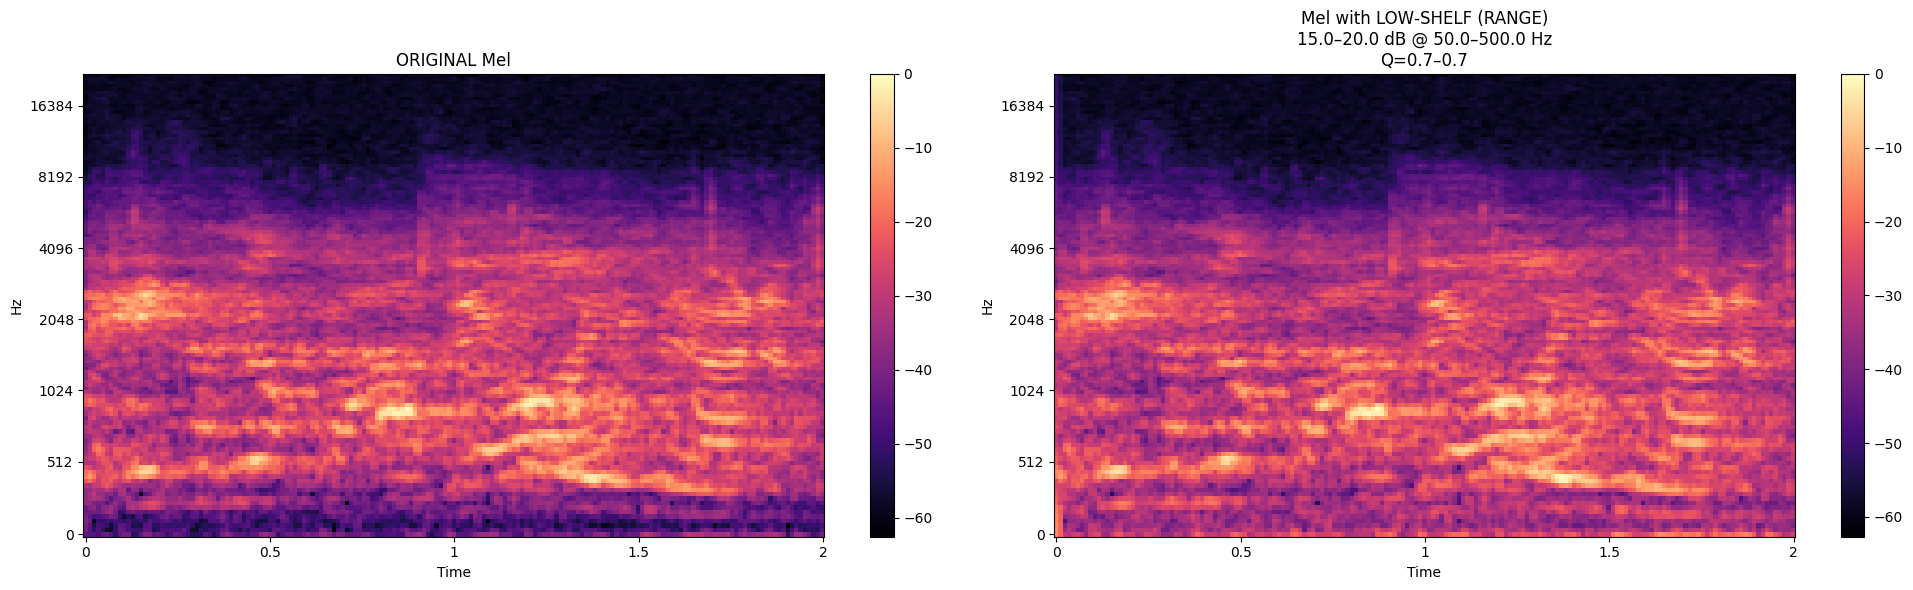

In [171]:
diagnostic_eq_lowshelf(
    LS_MIN_CENTER,
    LS_MAX_CENTER,
    LS_MIN_GAIN,
    LS_MAX_GAIN,
    LS_MIN_Q,
    LS_MAX_Q,
    LS_P
)

### Flanger

In [ ]:
# PARAMETERS

FLG_DELAY_MS  = 1.0     # base delay (typical 2–5 ms)
FLG_DEPTH_MS  = 0.1     # modulation depth (0.5–3 ms)
FLG_RATE_HZ   = 1       # LFO frequency (0.1–1 Hz smooth)
FLG_FEEDBACK  = 0.1     # feedback (0–0.4 very safe)
FLG_MIX       = 0.9    # dry/wet mix (0.2–0.6 ideal)

In [ ]:
# FUNCTION

def apply_flanger_dsp(y, sr, delay_ms=2.0, depth_ms=1.2, rate_hz=0.4, feedback=0.25, mix=0.45):
    """
    Professional DSP flanger:
    - Delay modulated by LFO
    - Linear interpolation
    - Soft feedback
    - Professional dry/wet mix
    Safe for ML Data Augmentation.
    """

    y = y.astype(np.float32)
    n = len(y)

    # samples
    delay_samp = (delay_ms / 1000.0) * sr
    depth_samp = (depth_ms / 1000.0) * sr

    # sine LFO
    t = np.arange(n) / sr
    lfo = np.sin(2 * np.pi * rate_hz * t)

    y_out = np.zeros(n, dtype=np.float32)
    fb = 0.0

    for i in range(n):
        current_delay = delay_samp + depth_samp * lfo[i]
        idx_float = i - current_delay

        if idx_float < 0:
            delayed = 0.0
        else:
            idx_int = int(idx_float)
            frac = idx_float - idx_int
            if idx_int + 1 < n:
                delayed = (1 - frac) * y[idx_int] + frac * y[idx_int + 1]
            else:
                delayed = y[idx_int]

        delayed = delayed + fb * feedback

        y_out[i] = (1 - mix) * y[i] + mix * delayed

        fb = delayed

    maxv = np.max(np.abs(y_out))
    if maxv > 0.99:
        y_out = y_out / maxv

    return y_out.astype(np.float32)


# DIAGNOSTIC

def diagnostic_flanger_dsp(delay_ms, depth_ms, rate_hz, feedback, mix):
    print("\n========================================")
    print("              DIAGNOSTIC — FLANGER DSP")
    print("========================================")
    print(f" Delay base       : {delay_ms} ms")
    print(f" Depth            : {depth_ms} ms")
    print(f" LFO Rate         : {rate_hz} Hz")
    print(f" Feedback         : {feedback}")
    print(f" Mix (dry/wet)    : {mix}")
    print("----------------------------------------\n")

    # choose random audio
    fname, ruta = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(ruta, sr=None)

    # apply flanger DSP
    y_fl = apply_flanger_dsp(
        y, sr,
        delay_ms=delay_ms,
        depth_ms=depth_ms,
        rate_hz=rate_hz,
        feedback=feedback,
        mix=mix
    )

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(data=y, rate=sr))

    # augmentated audio
    print("\n🔊 AUDIO WITH FLANGER DSP:")
    display(Audio(data=y_fl, rate=sr))

    # Mel spectrograms
    mel_o = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_f = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_fl, sr=sr),
        ref=np.max
    )

    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # flanger Mel
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_f, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(
        f"Mel with FLANGER DSP\n"
        f"{delay_ms}ms | depth={depth_ms}ms | rate={rate_hz}Hz | fb={feedback} | mix={mix}"
    )
    plt.colorbar()

    plt.tight_layout()
    plt.show()


              DIAGNOSTIC — FLANGER DSP
 Delay base       : 1.0 ms
 Depth            : 0.1 ms
 LFO Rate         : 1 Hz
 Feedback         : 0.1
 Mix (dry/wet)    : 0.9
----------------------------------------

🎵 Selected audio: 006_44_P2.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH FLANGER DSP:


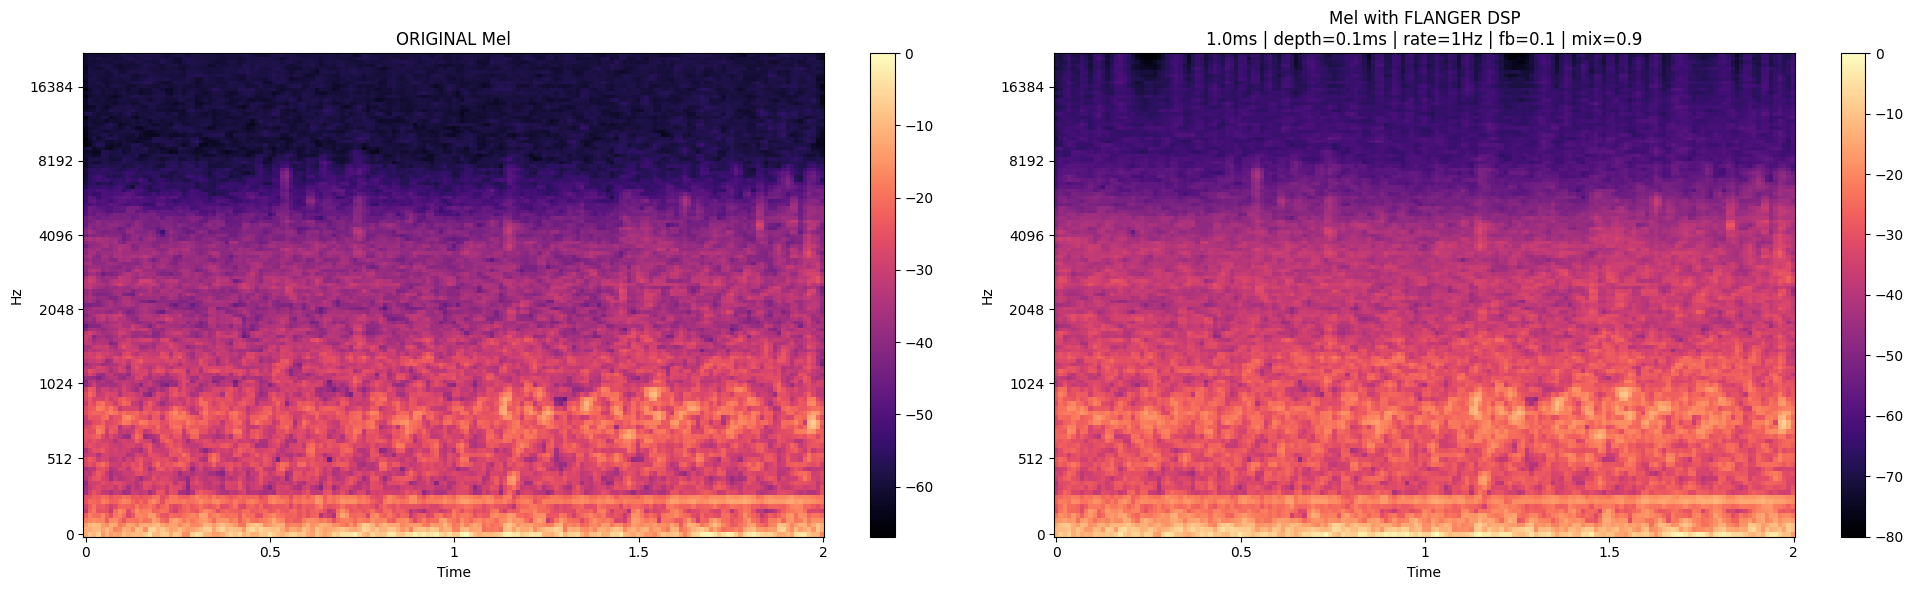

In [67]:
diagnostic_flanger_dsp(
    FLG_DELAY_MS,
    FLG_DEPTH_MS,
    FLG_RATE_HZ,
    FLG_FEEDBACK,
    FLG_MIX
)

### Chorus

In [ ]:
#PARAMETERS

CHR_RATE_HZ   = 1.2     # modulation frequency (0.3–1.5 Hz recommended)
CHR_DEPTH     = 0.8     # depth (0.05–0.3 safe)
CHR_DELAY_MS  = 15.0    # base delay (5–15 ms typical)
CHR_FEEDBACK  = 0.3     # feedback (0–0.3)
CHR_MIX       = 0.6     # dry/wet mix (0.1–0.4 ideal)

In [ ]:
# FUNCTION

def apply_chorus_pedalboard(y, sr,
                            rate_hz=CHR_RATE_HZ,
                            depth=CHR_DEPTH,
                            delay_ms=CHR_DELAY_MS,
                            feedback=CHR_FEEDBACK,
                            mix=CHR_MIX):

    """
    Professional chorus using pedalboard (Spotify).
    Soft parameters for ML DA.
    """

    effect = Pedalboard([
        Chorus(
            rate_hz=rate_hz,
            depth=depth,
            centre_delay_ms=delay_ms,
            feedback=feedback,
            mix=mix
        )
    ])

    # Pedalboard operates on float32
    y_proc = effect(y.astype(np.float32), sr)
    return y_proc.astype(np.float32)


# DIAGNOSTIC
def diagnostic_chorus(rate_hz, depth, delay_ms, feedback, mix):
    print("\n========================================")
    print("        DIAGNOSTIC — CHORUS (pedalboard)")
    print("========================================")
    print(f" Rate (Hz)       : {rate_hz}")
    print(f" Depth           : {depth}")
    print(f" Delay (ms)      : {delay_ms}")
    print(f" Feedback        : {feedback}")
    print(f" Mix (dry/wet)   : {mix}")
    print("----------------------------------------\n")

    # random audio
    fname, ruta = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(ruta, sr=None)

    # apply chorus
    y_chr = apply_chorus_pedalboard(
        y, sr,
        rate_hz,
        depth,
        delay_ms,
        feedback,
        mix
    )

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(y, rate=sr))

    # chorus audio
    print("\n🔊 AUDIO WITH CHORUS:")
    display(Audio(y_chr, rate=sr))

    # Mels
    mel_o = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_c = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_chr, sr=sr),
        ref=np.max
    )

    plt.figure(figsize=(20, 6))

    # original
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # chorus
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_c, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(
        f"Mel with CHORUS\n"
        f"rate={rate_hz}Hz | depth={depth} | delay={delay_ms}ms\n"
        f"fb={feedback} | mix={mix}"
    )
    plt.colorbar()

    plt.tight_layout()
    plt.show()


        DIAGNOSTIC — CHORUS (pedalboard)
 Rate (Hz)       : 1.2
 Depth           : 0.8
 Delay (ms)      : 15.0
 Feedback        : 0.3
 Mix (dry/wet)   : 0.6
----------------------------------------

🎵 Selected audio: 059_52_P2.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH CHORUS:


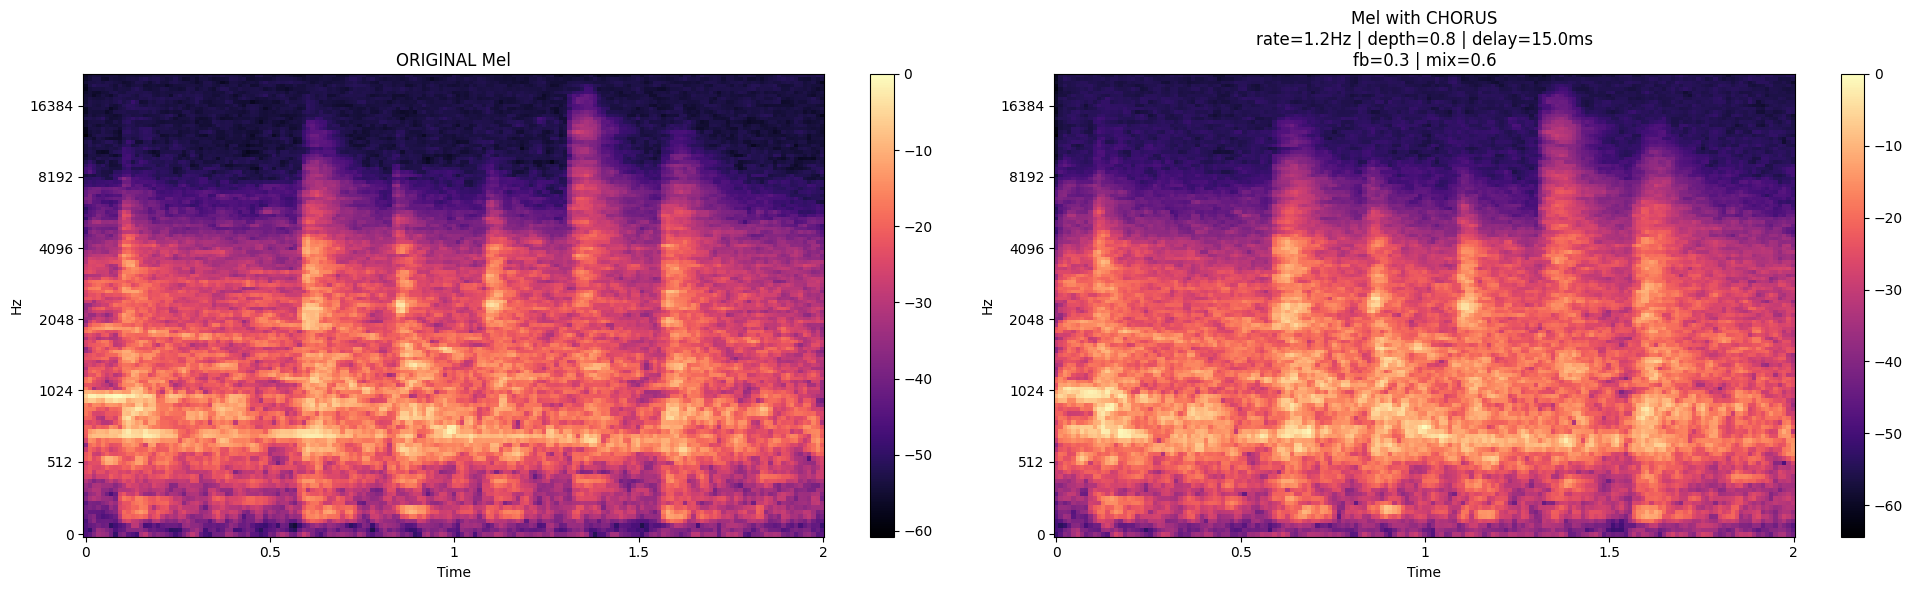

In [83]:
diagnostic_chorus(
    CHR_RATE_HZ,
    CHR_DEPTH,
    CHR_DELAY_MS,
    CHR_FEEDBACK,
    CHR_MIX
)

### Phaser

In [ ]:
# PARAMETERS

PH_RATE_HZ   = 2.0      # modulation frequency (0.1–1.5 Hz recommended)
PH_DEPTH     = 2.0      # depth (0–1)
PH_CENTER    = 2000    # center frequency (200–2000 Hz)
PH_FEEDBACK  = 0.5      # feedback (0–0.4)
PH_MIX       = 1.0      # dry/wet mix (0.2–0.6)

In [ ]:
# FUNCTION

def apply_phaser_pedalboard(y, sr,
                            rate_hz=PH_RATE_HZ,
                            depth=PH_DEPTH,
                            centre_frequency=PH_CENTER,
                            feedback=PH_FEEDBACK,
                            mix=PH_MIX):

    effect = Pedalboard([
        Phaser(
            rate_hz=rate_hz,
            depth=depth,
            centre_frequency_hz=centre_frequency,
            feedback=feedback,
            mix=mix
        )
    ])

    y_proc = effect(y.astype(np.float32), sr)
    return y_proc.astype(np.float32)


# DIAGNOSTIC

def diagnostic_phaser(rate_hz, depth, centre_frequency, feedback, mix):
    print("\n========================================")
    print("        DIAGNOSTIC — PHASER (pedalboard)")
    print("========================================")
    print(f" Rate (Hz)       : {rate_hz}")
    print(f" Depth           : {depth}")
    print(f" Center Freq     : {centre_frequency} Hz")
    print(f" Feedback        : {feedback}")
    print(f" Mix (dry/wet)   : {mix}")
    print("----------------------------------------\n")

    # random audio
    fname, ruta = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(ruta, sr=None)

    # apply Phaser
    y_ph = apply_phaser_pedalboard(
        y, sr,
        rate_hz,
        depth,
        centre_frequency,
        feedback,
        mix
    )

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(y, rate=sr))

    # phaser audio
    print("\n🔊 AUDIO WITH PHASER:")
    display(Audio(y_ph, rate=sr))

    # Mels
    mel_o = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )

    mel_p = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_ph, sr=sr),
        ref=np.max
    )

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_p, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title(
        f"Mel with PHASER\n"
        f"rate={rate_hz}Hz | depth={depth}\n"
        f"center={centre_frequency}Hz | fb={feedback} | mix={mix}"
    )
    plt.colorbar()

    plt.tight_layout()
    plt.show()


        DIAGNOSTIC — PHASER (pedalboard)
 Rate (Hz)       : 2.0
 Depth           : 2.0
 Center Freq     : 2000 Hz
 Feedback        : 0.5
 Mix (dry/wet)   : 1.0
----------------------------------------

🎵 Selected audio: 070_16_P1.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH PHASER:


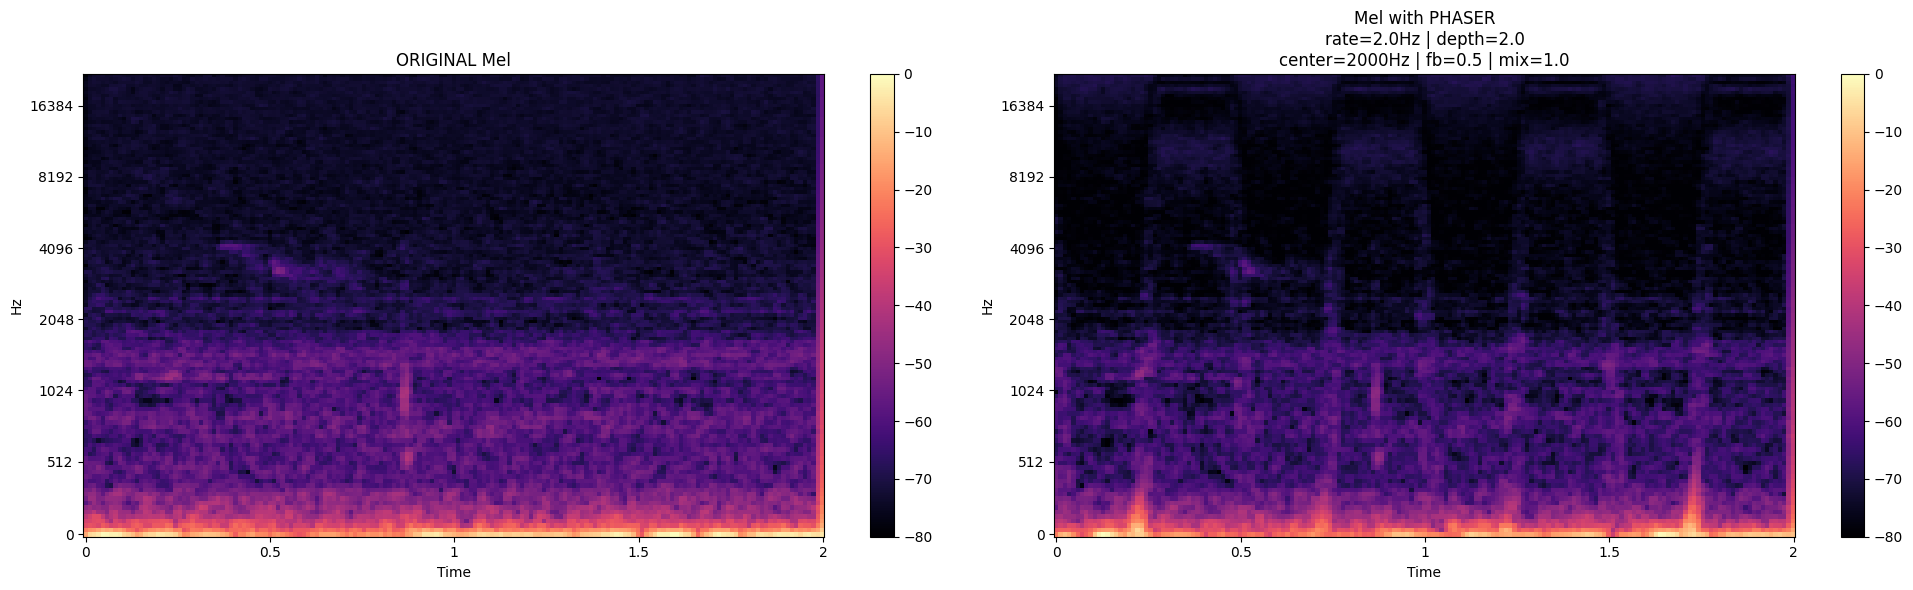

In [127]:
diagnostic_phaser(
    PH_RATE_HZ,
    PH_DEPTH,
    PH_CENTER,
    PH_FEEDBACK,
    PH_MIX
)

### Repeat

In [ ]:
# PARAMETERS

RP_MIN_REPEATS   = 1
RP_MAX_REPEATS   = 2

RP_MIN_DURATION  = 0.20   # in seconds
RP_MAX_DURATION  = 0.60   # in seconds

RP_P             = 1.0    # always apply for diagnostic
RP_MODE          = "insert"   # or "replace"

In [ ]:
# DIAGNOSTIC

def diagnostic_rp(min_repeats, max_repeats,
                  min_duration, max_duration,
                  mode, p):

    print("\n========================================")
    print("              DIAGNOSTIC — REPEAT PART")
    print("========================================")
    print(f" repeats      : {min_repeats} → {max_repeats}")
    print(f" durations    : {min_duration}s → {max_duration}s")
    print(f" mode         : {mode}")
    print(f" probability  : {p}")
    print("----------------------------------------\n")

    # choose random audio
    fname, ruta = select_audio_random(train_df, ORG_AUDIO_DIR)
    print(f"🎵 Selected audio: {fname}\n")

    # load audio
    y, sr = librosa.load(ruta, sr=None)

    # create RepeatPart
    rp = RepeatPart(
        min_repeats=min_repeats,
        max_repeats=max_repeats,
        min_part_duration=min_duration,
        max_part_duration=max_duration,
        mode=mode,
        crossfade_duration=0,
        p=p
    )

    # apply effect directly
    y_rp = rp(samples=y, sample_rate=sr)

    # original audio
    print("🔊 ORIGINAL AUDIO:")
    display(Audio(y, rate=sr))

    # repeatPart audio
    print("\n🔊 AUDIO WITH REPEATPART:")
    display(Audio(y_rp, rate=sr))

    # Mel spectrograms
    mel_o = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y, sr=sr),
        ref=np.max
    )
    mel_r = librosa.power_to_db(
        librosa.feature.melspectrogram(y=y_rp, sr=sr),
        ref=np.max
    )

    plt.figure(figsize=(20, 6))

    # original Mel
    plt.subplot(1, 2, 1)
    librosa.display.specshow(mel_o, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("ORIGINAL Mel")
    plt.colorbar()

    # repeatPart Mel
    plt.subplot(1, 2, 2)
    librosa.display.specshow(mel_r, sr=sr, x_axis='time', y_axis='mel', cmap='magma')
    plt.title("Mel with REPEATPART")
    plt.colorbar()

    plt.tight_layout()
    plt.show()


              DIAGNOSTIC — REPEAT PART
 repeats      : 1 → 2
 durations    : 0.2s → 0.6s
 mode         : insert
 probability  : 1.0
----------------------------------------

🎵 Selected audio: 037_68_P2.wav

🔊 ORIGINAL AUDIO:



🔊 AUDIO WITH REPEATPART:


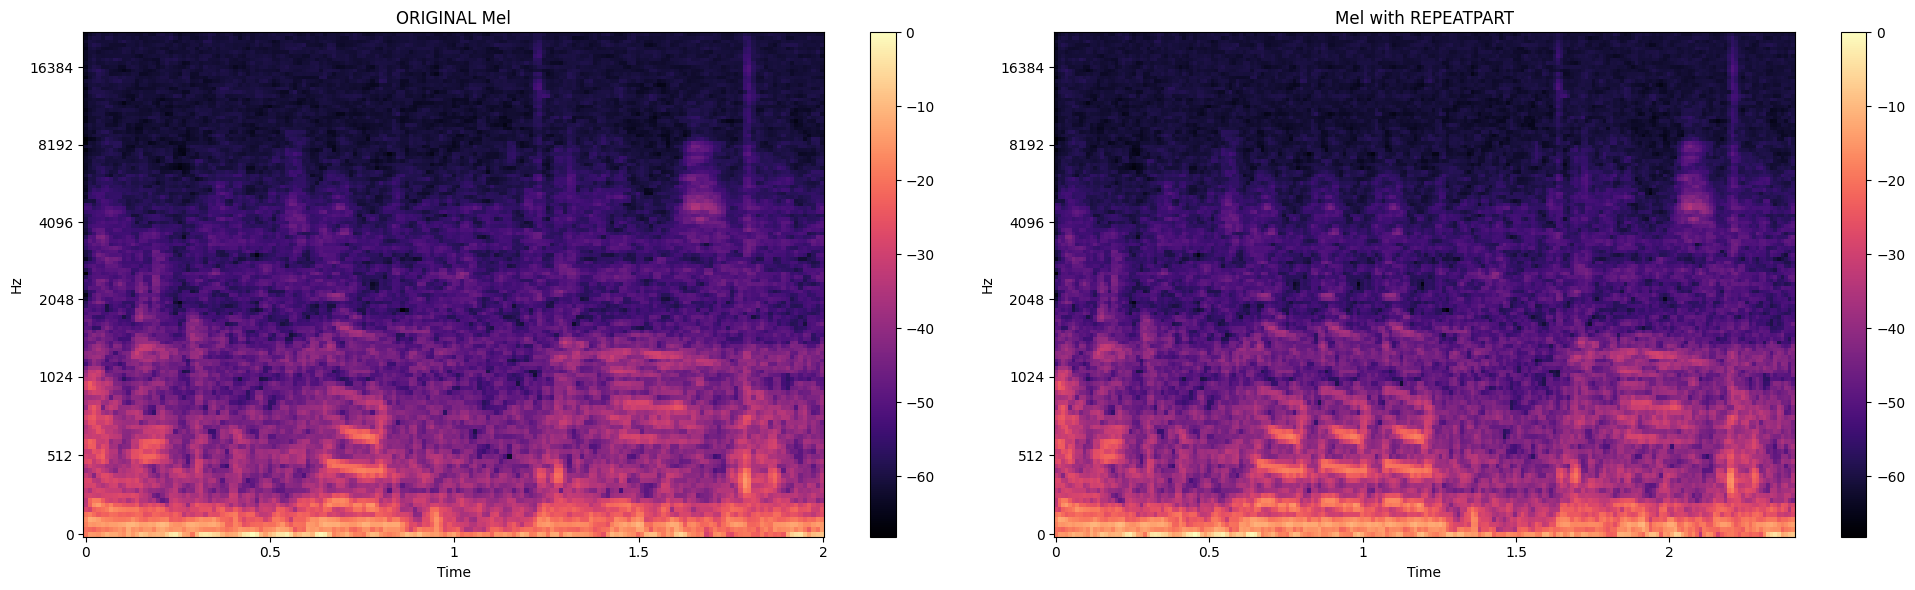

In [145]:
diagnostic_rp(
    RP_MIN_REPEATS,
    RP_MAX_REPEATS,
    RP_MIN_DURATION,
    RP_MAX_DURATION,
    RP_MODE,
    RP_P
)